# Billboard: Top 10 or Not?

BA780 Team Assignment — Team A05

Team members: Muhammad Azaan, Omar Tawfik, Caitlin Jeng, Xiaoquan Dai

---

#### How this notebook is organised

| Section | What you will find |
|---|---|
| Executive summary | The answer in one paragraph, plus a table of the findings |
| 1. Problem definition | The target, the songs we study, and the rule that every predictor must be known at debut |
| 2. Data description | The three data sources and how they join |
| 3. Data cleaning | A step-by-step rebuild of the dataset from the raw files (skip it if you only want the findings) |
| 4. Exploratory questions | Data checks (4.0), then 15 questions in five themes, each with a test and a chart |
| 5. Conclusion | Ranked insights, risks and limitations, next steps |
| 6-7. References and AI use | Sources, software and how we used AI |

Every question in Section 4 has the same five parts: the research question, the data analysis, the chart, the
finding with its numbers, and an interpretation that avoids claiming cause and effect. Every chart has a headline
that states its result.

#### Research question

Among songs that reached the Billboard Hot 100 between January 2018 and September 2026,
what distinguishes those that climbed into the Top 10 from those that peaked lower?

#### Why this matters

These findings show that a song’s commercial success is more closely associated with artist history, release strategy, and genre than with measurable lyrical features. This matters because it helps artists, labels, and marketers focus on the factors that are more closely associated with chart performance. It also highlights the importance of careful statistical testing, since apparent patterns can disappear once confounding effects and data leakage are addressed.


#### Data sources, access and licensing

| Source | What we used | Access URL | Licence |
|---|---|---|---|
| Billboard Hot 100 weekly archive (mhollingshead) | every weekly chart, 1958-2026 | https://github.com/mhollingshead/billboard-hot-100 | No licence declared by the repository. The underlying chart is Billboard's copyrighted compilation |
| LRCLIB | song lyrics | https://lrclib.net/docs | No licence stated on the public docs page. Lyrics remain the rights holders' property |
| MusicBrainz | release dates, release type, genres, artist metadata | https://musicbrainz.org/doc/MusicBrainz_API | Core data CC0 / public domain; some supplementary data CC-BY-NC-SA |

We checked each source rather than assuming. Only MusicBrainz's licence is explicit.
The other two are used here for non-commercial academic analysis only, and neither
the raw lyrics nor the chart archive should be redistributed from this repository.
This is revisited in *Risks and limitations*.

#### Reproducibility

Runs top to bottom with Restart & Run All, using relative paths only. Section 3 rebuilds the
cleaned dataset from the raw files in `data/raw/` (`all.json`, `lyrics.csv`, `mb_songs.csv`,
`mb_artists.csv`) and checks it against `data/clean/songs_analysis.csv`, which the analysis in
Section 4 reads. In Colab, the first cell asks you to upload any file that is missing.
It makes no API calls: the lyrics and MusicBrainz files are the saved results of our
earlier API requests. NumPy is seeded at 42.

In [1]:
# Run me first: make sure the raw files and the analysis file are in place.
import os

NEEDED = {
    "all.json":           "data/raw/all.json",            # Billboard weekly archive
    "lyrics.csv":         "data/raw/lyrics.csv",          # LRCLIB results
    "mb_songs.csv":       "data/raw/mb_songs.csv",        # MusicBrainz recordings
    "mb_artists.csv":     "data/raw/mb_artists.csv",      # MusicBrainz artists
    "songs_analysis.csv": "data/clean/songs_analysis.csv",  # cleaned file used in Section 4
}
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

missing = [name for name, path in NEEDED.items() if not os.path.exists(path)]
if missing:
    try:
        from google.colab import files       # Colab: upload the missing files in one go
        print("Please upload:", ", ".join(missing))
        files.upload()
        for name in missing:
            os.replace(name, NEEDED[name])
    except ImportError:                      # local Jupyter: the files must already be there
        raise FileNotFoundError(f"Place these files (from the team Drive) at: {[NEEDED[m] for m in missing]}")
for name, path in NEEDED.items():
    print(f"ready: {path}")


ready: data/raw/all.json
ready: data/raw/lyrics.csv
ready: data/raw/mb_songs.csv
ready: data/raw/mb_artists.csv
ready: data/clean/songs_analysis.csv


In [2]:
# Setup: load the libraries, set the random seed and chart style, then read the dataset.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(42)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 60)

# Chart style: slate and clay. Slate marks the point of each chart, warm stone is context,
# and clay marks a second group (newcomers) when two groups are compared.
FOCUS, SECOND, CONTEXT, PALE = "#356C93", "#E0814D", "#DCD5C9", "#ECE7DE"
FOCUS_LIGHT, FOCUS_PALE = "#8DB0CA", "#C8D9E6"    # lighter slate for filled boxes, so median lines stay visible
GOLD, CORAL, SEAFOAM = "#EDB548", "#DB6440", "#7DB5AA"   # extra tones for the five-genre chart (Chart 15)
REF = "#A39E95"                                  # reference lines and outlines
BACKGROUND = "#F8F6F1"                           # warm off-white background
TEXT, MUTED = "#2B3036", "#6A7078"
SOURCE = "Source: Billboard Hot 100 archive and MusicBrainz · songs that debuted 2018–2024"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10.5,
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "savefig.facecolor": BACKGROUND,
    "text.color": TEXT,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": "#BDB6AA",
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "grid.color": "#E7E2D9",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

# Display names for genres, in sentence case.
GENRE_NAMES = {"pop": "Pop", "hip-hop/rap": "Hip-hop/rap", "R&B": "R&B", "country": "Country",
               "Latin": "Latin", "rock/alternative": "Rock/alternative", "dance/electronic": "Dance/electronic",
               "mixed": "Mixed (tied genres)", "other": "Other"}

def chart_titles(ax, number, headline, subtitle, source=SOURCE, extra_space=0):
    """Put 'CHART n', a one-line headline and a subtitle above the plot, and a source line below it.
    extra_space lifts the titles when the plot already has panel titles on top."""
    def text_above(text, offset, **style):
        ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, offset), textcoords="offset points",
                    ha="left", va="bottom", gid="chart-title", **style)
    y = 12 + extra_space
    text_above(subtitle, y, fontsize=10, color=MUTED)
    y += 14 * (subtitle.count("\n") + 1) + 6
    text_above(headline, y, fontsize=13.5, fontweight="bold", color=TEXT)
    y += 24
    text_above(f"CHART {number}", y, fontsize=8.5, fontweight="bold", color=MUTED)
    ax.figure.text(0, 0, source, fontsize=8, color=MUTED, ha="left", va="bottom", gid="chart-source")

def show_chart(fig):
    """Lay the chart out, keep the source line under the plot's left edge, then display it."""
    titles = [t for ax in fig.axes for t in ax.texts if t.get_gid() == "chart-title"]
    for t in titles:
        t.set_in_layout(False)                  # titles sit above the plot; leave them out of the layout maths
    fig.tight_layout(rect=(0, 24 / (fig.get_figheight() * 72), 1, 1))
    for t in titles:
        t.set_in_layout(True)                   # ...but keep them in the saved image
    left = min(ax.get_position().x0 for ax in fig.axes)
    for t in fig.texts:
        if t.get_gid() == "chart-source":
            t.set_position((left, 0.004))
    plt.show()

DATA = "data/clean/songs_analysis.csv"
df = pd.read_csv(DATA)
df["top10"] = df["top10"].astype(bool)

print(f"loaded {DATA}: {len(df):,} rows x {len(df.columns)} columns")

loaded data/clean/songs_analysis.csv: 5,342 rows x 71 columns


## Executive summary

We built a dataset of 5,342 songs that entered the Billboard Hot 100 between January 2018 and September 2026,
joining the weekly chart archive to lyrics (LRCLIB, 99.4% matched) and release metadata (MusicBrainz, 99.0%
matched). 519 of them (9.7%) reached the Top 10. All tests use the 4,293 songs that debuted in 2018-2024.

The strongest associations are not about the song itself. Who the artist is (their track record and reach), how a
song is released and its genre are associated with much larger differences than anything we can measure in the lyrics.
Every main result was checked against its most likely confounder, and all results are associations, not causes.

#### Findings at a glance

| Theme | What we found | Questions |
|---|---|---|
| Genre | Pop reaches the Top 10 at 18.7%, country at 5.3%. The gap remains among songs that were the artist's only debut that week. Artists with a previous hit have higher rates in every large genre | Q1, Q1a, Q1b |
| Artist track record | 18.5% for artists with 10 or more previous Top 10s (counted at debut) vs 5.8% for none. Hit ratio is at least as telling (3.7% at 0% vs 15.6% above 25%). A first-time entrant (9.4%) does far better than an artist with 11+ entries and no hit (2.3%) | Q2, Q2a, Q2b |
| Artist reach | Ten artists produced 37% of Top 10 songs. Outside-US artists reach the Top 10 at 15.8% vs 9.0% for US artists, a gap that holds within previous-hit groups but is carried largely by a few stars | Q3, Q3a, Q3b |
| Release strategy | Songs that are the artist's only debut that week reach the Top 10 at 11.6%; with 5-9 same-week debuts, 2.1%. The pattern holds in hip-hop and pop, and the singles advantage disappears among songs debuting alone | Q4, Q4a, Q4b |
| Timing and lyrics | The May/November "season" disappears once same-artist debut weeks are removed. Country's share of Top 10 songs rose from 2.2% to 11.6%. Lyric measures barely separate hits | Q5, Q5a, Q5b |

We recommend treating artist track record, same-week debuts and genre as the main candidate predictors for the
modelling phase, and treating lyric-based features as weak unless richer content features are added.

**So what:** who released the song, and how, is associated with far more of the difference than what the song says.

## 1. Problem definition

Business framing. A label deciding where to put marketing money wants to know which
songs have a realistic chance of a Top 10 placing, and which levers actually move that
chance. "Make a better song" is not actionable; "release this as a standalone single
rather than as track nine of an album" is.

Analytical framing. A binary classification target with a class imbalance:

- Unit of analysis: one song, identified by its Billboard title and its debut-week credit.
- Target: `top10` — did the song ever reach positions 1-10 during its chart run?
- Population: songs whose *first* chart appearance falls on or after 2018-01-01.
  Songs that debuted earlier are excluded even if they charted into the window, so
  every song is observed from the start of its run.
- Predictors: everything knowable at the song's debut week — the artist's prior
  chart record, genre, lyrics, release metadata, and how many songs the artist put on
  the chart that same week.

The constraint that shapes everything below. Every predictor must be knowable at
debut. An artist's history counts only songs that debuted *strictly earlier*; lyrics are
taken from the credit the song debuted under, so a verse added by a later featured
artist cannot leak backwards. A previous song only counts as a Top 10 hit if it had reached the Top 10
before the debut (Section 4.0c), and the methodology note in Section 4.6 shows what happens when this
discipline slips.

Two exclusions.

1. Songs still on the chart (`in_model == False`) have no final peak, so no reliable
   label. They stay in the file for description but are dropped from every test.
2. 2025-2026 songs are held out as a test set. All hypothesis testing below runs on
   the 2018-2024 training years, so the choices we make here cannot quietly overfit the
   data a future model will be judged on.

   Success criteria. This phase succeeds if it delivers two things: a clean, documented dataset of every 2018–2026 Hot 100 song with only debut-week predictors, and a ranked list of the factors that genuinely separate Top 10 hits from lower-peaking songs. We count a factor as meaningful only if the difference is statistically significant (p < 0.05) and at least a small effect (Cramér's V ≥ 0.1), since with thousands of songs even trivial differences can pass a significance test. In the final phase, success means a prediction model trained on 2018–2024 that identifies Top 10 hits in the held-out 2025–2026 songs better than a simple baseline using artist history alone, judged by precision and recall rather than accuracy.

In [3]:
# Split songs into training years (2018-2024) and held-out test years (2025-2026).
# Every test below uses the training years only.
train = df[df["model_split"] == "train"].copy()
test = df[df["model_split"] == "test"].copy()
excluded = df[~df["in_model"]]

print(f"all songs          {len(df):>6,}")
print(f"  train 2018-2024  {len(train):>6,}   Top 10: {train['top10'].sum():>4} ({train['top10'].mean()*100:.1f}%)")
print(f"  test  2025-2026  {len(test):>6,}   held out, untouched below")
print(f"  no final peak    {len(excluded):>6,}   still charting, dropped from all tests")

all songs           5,342
  train 2018-2024   4,293   Top 10:  441 (10.3%)
  test  2025-2026     950   held out, untouched below
  no final peak        99   still charting, dropped from all tests


**So what:** we are predicting a 1-in-10 event, using only what a label would know on release week.

## 2. Data description

Three sources, joined on the song's debut-week credit.

| Source | Grain | Rows retrieved | Matched |
|---|---|---|---|
| Billboard weekly archive | one row per song per chart week | 3,555 weekly charts, 1958-2026 | n/a (this is the spine) |
| LRCLIB | one row per song | 5,377 fetched | 99.4% at or above the match threshold |
| MusicBrainz | one recording + its artists per song | 5,349 songs, 1,269 artists | 99.0% |

The archive reaches back to 1958 even though the study window starts in 2018, because
an artist's *prior* record has to be counted from the whole of chart history. Drake's
"prior entries" figure is meaningless if we only look back to 2018.

Matching to LRCLIB and MusicBrainz is fuzzy, so every match carries a confidence score
(0-100) and the search that found it. We treat 72+ as trusted; below that the row keeps
its data for inspection but is not counted as matched.

In [4]:
# Overview of the dataset: column types and summary statistics for the key columns.
print("Shape and dtypes\n" + "-" * 60)
df.info(max_cols=0, memory_usage=True)

key = ["top10", "peak_position", "weeks_on_chart", "debut_position",
       "prior_top10s", "prior_entries", "word_count", "unique_word_ratio",
       "same_artist_debuts_that_week"]
print("\n\nNumeric summary of the key columns\n" + "-" * 60)
display(df[key].describe().T.round(3))

Shape and dtypes
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 5342 entries, 0 to 5341
Columns: 71 entries, title to model_split
dtypes: bool(16), float64(11), int64(15), object(2), str(27)
memory usage: 2.3+ MB


Numeric summary of the key columns
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
peak_position,5342.0,51.168,28.402,1.000,27.000,53.000,75.000,100.000
weeks_on_chart,5342.0,8.180,11.168,1.000,1.000,2.000,12.000,112.000
debut_position,5342.0,60.530,29.139,1.000,38.000,65.000,87.000,100.000
prior_top10s,5342.0,7.228,13.409,0.000,0.000,2.000,8.000,80.000
prior_entries,5342.0,45.133,64.859,0.000,5.000,20.000,58.000,362.000
word_count,5310.0,447.505,193.845,7.000,310.000,410.000,555.000,1711.000
unique_word_ratio,5310.0,0.364,0.085,0.071,0.308,0.359,0.414,0.903
same_artist_debuts_that_week,5342.0,6.995,7.942,1.000,1.000,2.000,12.000,40.000


In [5]:
# How many songs reached the Top 10, overall and per debut year.
print("Target balance")
counts = df["top10"].value_counts()
for label, n in counts.items():
    print(f"  {'Top 10' if label else 'peaked 11-100':<15} {n:>5,}  ({n/len(df)*100:.1f}%)")

print("\nSongs per debut year")
display(
    df.groupby("debut_year")
      .agg(songs=("title", "size"), top10=("top10", "sum"))
      .assign(top10_rate_pct=lambda t: (t["top10"] / t["songs"] * 100).round(1))
)

Target balance
  peaked 11-100   4,823  (90.3%)
  Top 10            519  (9.7%)

Songs per debut year


,songs,top10,top10_rate_pct
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


**So what:** the target is stable at roughly one in ten across all nine years, so no year dominates the signal.

## 3. Data cleaning

If you only want the findings, skip to Section 4.

This section rebuilds the analysis dataset from the raw files, one step per cell, using only
methods from the course: loops and functions with `re` (Module 00), `read_csv` / `read_json`
(04), `isna`, `fillna`, `to_datetime` and `missingno` (05), `groupby` with `agg` / `transform`
(06), and `merge` (09).

The lyrics and MusicBrainz files are the saved results of our API calls, one row per chart
credit, so no API is called here. The rebuild covers the columns the analysis uses. Step 11
compares it with `data/clean/songs_analysis.csv`, the file Section 4 reads.

| Step | What it does |
|---|---|
| 0 | Load the raw files |
| 1 | Inspect types, gaps and duplicates |
| 2 | One row per chart credit |
| 3 | Split each credit into artists |
| 4 | Merge renamed credits into one song |
| 5 | Each artist's chart history before the song |
| 6 | Keep 2018 onward and add the target |
| 7 | Join lyrics and MusicBrainz |
| 8 | Broad genre |
| 9 | Duration and lyric features |
| 10 | Release timing and album drops |
| 11 | Missing values, save and compare |

### Step 0. Load the raw files

In [6]:
# Step 0: all.json holds every weekly Hot 100 chart since 1958, as a list of weeks.
import json, re
import numpy as np
import pandas as pd

with open("data/raw/all.json") as f:
    charts = json.load(f)

# Turn each week into a small DataFrame, then stack them (same pattern as the Mevgal example).
frames = []
for week in charts:
    week_df = pd.DataFrame(week["data"])
    week_df["date"] = week["date"]
    frames.append(week_df)
weekly = pd.concat(frames, ignore_index=True)

lyrics_raw = pd.read_csv("data/raw/lyrics.csv")        # LRCLIB, one row per chart credit
mb_songs   = pd.read_csv("data/raw/mb_songs.csv")      # MusicBrainz recordings, one row per credit
mb_artists = pd.read_csv("data/raw/mb_artists.csv")    # MusicBrainz artists

print(f"weekly chart rows: {len(weekly):,}  lyrics: {len(lyrics_raw):,}  "
      f"mb_songs: {len(mb_songs):,}  mb_artists: {len(mb_artists):,}")
weekly.head()

weekly chart rows: 355,487  lyrics: 5,377  mb_songs: 5,349  mb_artists: 1,269


,song,artist,this_week,last_week,peak_position,weeks_on_chart,date
0,Poor Little Fool,Ricky Nelson,1,None,1,1,1958-08-04
1,Patricia,Perez Prado And His Orchestra,2,None,2,1,1958-08-04
2,Splish Splash,Bobby Darin,3,None,3,1,1958-08-04
3,Hard Headed Woman,Elvis Presley With The Jordanaires,4,None,4,1,1958-08-04
4,When,Kalin Twins,5,None,5,1,1958-08-04


### Step 1. Inspect types, gaps and duplicates

In [7]:
# Step 1: the date is text, so convert it; then check for gaps and duplicate rows.
weekly["date"] = pd.to_datetime(weekly["date"])
weekly.info()

print("\nmissing values:\n", weekly.isna().sum())        # last_week is blank in a song's first week
print("duplicate song/artist/week rows:", weekly.duplicated(["song", "artist", "date"]).sum())
print("duplicate credits in lyrics:", lyrics_raw.duplicated(["title", "artist"]).sum(),
      "| in mb_songs:", mb_songs.duplicated(["title", "artist"]).sum(),
      "| duplicate artist ids:", mb_artists.duplicated("artist_mbid").sum())

<class 'pandas.DataFrame'>
RangeIndex: 355487 entries, 0 to 355486
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   song            355487 non-null  str           
 1   artist          355487 non-null  str           
 2   this_week       355487 non-null  int64         
 3   last_week       319130 non-null  object        
 4   peak_position   355487 non-null  int64         
 5   weeks_on_chart  355487 non-null  int64         
 6   date            355487 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(3), object(1), str(2)
memory usage: 19.0+ MB

missing values:
 song                  0
artist                0
this_week             0
last_week         36357
peak_position         0
weeks_on_chart        0
date                  0
dtype: int64


duplicate song/artist/week rows: 13
duplicate credits in lyrics: 0 | in mb_songs: 0 | duplicate artist ids: 0


### Step 2. One row per chart credit

The archive repeats a song every week it charts. Grouping by title and credit gives one row
each, with its first and last week, best position, weeks on chart and debut position.

In [8]:
# Step 2: sort by date so 'first' is the debut week, then groupby + agg.
# top10_date is the chart date only in weeks the song sat in the Top 10, so its minimum is the
# date the song first reached the Top 10 (blank for songs that never did).
weekly["top10_date"] = weekly["date"]
weekly.loc[weekly["this_week"] > 10, "top10_date"] = pd.NaT
credits = (weekly.sort_values("date")
                 .groupby(["song", "artist"])
                 .agg(first_chart_date=("date", "min"),
                      first_top10_date=("top10_date", "min"),
                      last_chart_date=("date", "max"),
                      peak_position=("this_week", "min"),
                      weeks_on_chart=("date", "count"),
                      debut_position=("this_week", "first"))
                 .reset_index())
print(f"{len(weekly):,} weekly rows -> {len(credits):,} credits")

355,487 weekly rows -> 32,723 credits


### Step 3. Split each credit into artists

"Drake Featuring 21 Savage & Project Pat" is three artists, but "Tyler, The Creator" is one.
Acts like that are protected: their "&", "," or " x" is hidden before splitting and put back
afterwards. The list is every MusicBrainz artist name containing "&" or ",", plus three acts we
found by hand ("Sonny & Cher", "Selena Gomez & The Scene", "Lil Nas X"). The separators include
Billboard's typos ("Feauring", "Featauring").

In [9]:
# Step 3: a function applied to every credit with .map (Modules 00 and 06).
# Names are compared in lower case, so "Tyler, the Creator" and "Tyler, The Creator" are the same artist.
# Protected acts: MusicBrainz names containing "&" or ",", plus three we found by checking credits by hand.
PROTECTED = [name.lower() for name in mb_artists["artist_name"].dropna().unique() if " & " in name or ", " in name]
PROTECTED += ["sonny & cher", "selena gomez & the scene", "lil nas x"]
SEPARATORS = r"\s+(?:featuring|feauring|featauring|feat\.|ft\.|a duet with|duet with|with|w/|x)\s+|\s*&\s*|\s*,\s*|:\s+|\s*\(\s*|\s*\)"

def split_artists(credit):
    credit = credit.lower()
    for act in PROTECTED:                                   # hide the separators inside protected acts
        if act in credit:
            credit = credit.replace(act, act.replace("&", "<amp>").replace(",", "<comma>").replace(" x", " <x>"))
    names = re.split(SEPARATORS, credit)
    return [n.replace("<amp>", "&").replace("<comma>", ",").replace("<x>", "x").strip() for n in names if n.strip()]

credits["credited"] = credits["artist"].map(split_artists)
credits["lead_artist"] = credits["credited"].map(lambda names: names[0])

print(len(PROTECTED), "protected acts, e.g.", PROTECTED[:4])
for c in ["Drake Featuring 21 Savage & Project Pat", "Tyler, The Creator Featuring Kali Uchis",
          "Lil Nas X Featuring Doja Cat", "Silk Sonic (Bruno Mars & Anderson .Paak)"]:
    print(f"  {c:42} -> {split_artists(c)}")

13 protected acts, e.g. ['tyler, the creator', 'for king & country', 'brooks & dunn', 'maddie & tae']
  Drake Featuring 21 Savage & Project Pat    -> ['drake', '21 savage', 'project pat']
  Tyler, The Creator Featuring Kali Uchis    -> ['tyler, the creator', 'kali uchis']
  Lil Nas X Featuring Doja Cat               -> ['lil nas x', 'doja cat']
  Silk Sonic (Bruno Mars & Anderson .Paak)   -> ['silk sonic', 'bruno mars', 'anderson .paak']


### Step 4. Merge renamed credits into one song

Billboard sometimes renames a credit mid-run ("Kanye West" became "Ye", a featured artist is
added), which splits one song into two rows and understates its peak. From 2018 onward, two
credits are merged when they have the same title and lead artist and the second starts within 28
days of the first one's last week. A plain parenthetical is ignored when comparing titles, but a
version marker (a year, "Remix", "Live", "Version", "Edit", "Mix", "Interlude") keeps the titles
apart, because those are different recordings.

In [10]:
# Step 4a: a key made of the cleaned title and the lead artist.
VERSION = r"\((\d{4}|.*remix.*|.*live.*|.*version.*|.*edit.*|.*mix.*|.*interlude.*)\)"

def title_key(title):
    title = title.lower()
    if re.search(VERSION, title):
        return title
    return re.sub(r"\s*\(.*?\)", "", title).strip()

lead_key = credits["lead_artist"].replace("kanye west", "ye")
in_window = credits["first_chart_date"] >= "2018-01-01"
credits["song_key"] = np.where(in_window,
                               credits["song"].map(title_key) + " | " + lead_key,
                               credits["song"] + " | " + credits["artist"])     # before 2018: never merged

# Step 4b: within a key, a credit continues the previous one only if it starts 1-28 days after
# the previous one's last week. Otherwise (co-charting, or a later re-recording) it is a new song.
credits = credits.sort_values(["song_key", "first_chart_date"])
previous_end = credits.groupby("song_key")["last_chart_date"].shift()
gap_days = (credits["first_chart_date"] - previous_end).dt.days
new_song = gap_days.isna() | (gap_days <= 0) | (gap_days > 28)
credits["song_id"] = new_song.cumsum()

# Step 4c: one row per song. The debut credit's title and artist are kept.
songs = (credits.sort_values("first_chart_date")
                .groupby("song_id")
                .agg(title=("song", "first"),
                     artist=("artist", "first"),
                     credited=("credited", "first"),
                     first_chart_date=("first_chart_date", "min"),
                     first_top10_date=("first_top10_date", "min"),
                     last_chart_date=("last_chart_date", "max"),
                     peak_position=("peak_position", "min"),
                     weeks_on_chart=("weeks_on_chart", "sum"),
                     debut_position=("debut_position", "first"),
                     n_credits=("song", "count"))
                .reset_index(drop=True))
print(f"{len(credits):,} credits -> {len(songs):,} songs ({(songs['n_credits'] > 1).sum()} songs were merged)")
songs[songs["n_credits"] > 1][["title", "artist", "peak_position", "weeks_on_chart", "n_credits"]].head()

32,723 credits -> 32,690 songs (32 songs were merged)


,title,artist,peak_position,weeks_on_chart,n_credits
412,360,Charli XCX,41,20,2
27468,Act II: Date @ 8,4Batz,7,20,2
27493,Ahi,Karol G & Drake,44,5,2
27617,Apple,Charli XCX,51,20,2
27768,BbY WOW,"Karol G, Judeline & rusowsky",10,5,2


### Step 5. Each artist's chart history before the song

For every credited artist we count their earlier chart entries and Top 10s, using the full
archive back to 1958. Songs debuting in the same week do not count as "earlier", so an album
drop does not give its own tracks a history.

Step 5c adds a stricter Top 10 count. An earlier song only counts as a hit if it had already
reached the Top 10 before this song's debut week, because a song that was still climbing was not
yet known to be a hit. Section 4 uses this strict count (see 4.0c).

In [11]:
# Step 5a: one row per (song, artist), built with a loop.
rows = []
for song_id, names, date, peak in zip(songs.index, songs["credited"], songs["first_chart_date"], songs["peak_position"]):
    for position, name in enumerate(names):
        rows.append({"song_id": song_id, "lead": position == 0, "date": date,
                     "artist_key": name.lower().replace("'", "").replace("’", ""), "top10": peak <= 10})
history = pd.DataFrame(rows).sort_values(["date", "song_id"])

# Step 5b: running totals per artist (cumsum), taken at the end of the previous week.
history["one"] = 1
for col, out in [("one", "prior_entries"), ("top10", "prior_top10s")]:
    history["running"] = history.groupby("artist_key")[col].cumsum()                 # includes this song
    through_week = history.groupby(["artist_key", "date"])["running"].transform("max")
    this_week = history.groupby(["artist_key", "date"])[col].transform("sum")
    history[out] = through_week - this_week                                          # strictly earlier weeks

# Step 5c: Top 10s already KNOWN at debut. prior_top10s counts earlier songs that eventually
# reached the Top 10, even if they got there after this song debuted. The stricter count only
# includes songs that had reached the Top 10 before this song's debut week.
history["top10_date"] = history["song_id"].map(songs["first_top10_date"])
hits = history.dropna(subset=["top10_date"])[["artist_key", "top10_date"]].rename(columns={"top10_date": "date"})
events = pd.concat([history[["artist_key", "date", "song_id", "lead"]].assign(is_hit=0), hits.assign(is_hit=1)])
events = events.sort_values(["artist_key", "date", "is_hit"])    # on the same date, the debut comes before the hit
events["hits_so_far"] = events.groupby("artist_key")["is_hit"].cumsum()
known_at_debut = events[events["is_hit"] == 0]

# The lead artist's history goes on the song; best_* is the best of all credited artists.
lead = history[history["lead"]].set_index("song_id")
songs["prior_entries"] = lead["prior_entries"]
songs["prior_top10s"] = lead["prior_top10s"]
songs["best_prior_top10s"] = history.groupby("song_id")["prior_top10s"].max()
songs["prior_top10s_known"] = known_at_debut[known_at_debut["lead"] == True].set_index("song_id")["hits_so_far"]
songs["best_prior_top10s_known"] = known_at_debut.groupby("song_id")["hits_so_far"].max()
songs[["title", "artist", "prior_entries", "prior_top10s", "prior_top10s_known"]].tail()

,title,artist,prior_entries,prior_top10s,prior_top10s_known
32685,Zombieboy,Lady Gaga,39,18,18
32686,Zoo York,Lil Tjay Featuring Fivio Foreign & Pop Smoke,4,0,0
32687,Zoo,Shakira,28,6,6
32688,Zoom,Lil Uzi Vert,88,7,7
32689,¿Dònde Està Santa Claus? (Where Is Santa Claus?),Augie Rios,0,0,0


### Step 6. Keep 2018 onward and add the target

In [12]:
# Step 6: filter to the study window, then add the target and the train/test split.
df_clean = songs[songs["first_chart_date"] >= "2018-01-01"].copy()

df_clean["top10"] = df_clean["peak_position"] <= 10
df_clean["debut_year"] = df_clean["first_chart_date"].dt.year
df_clean["in_model"] = df_clean["last_chart_date"] < weekly["date"].max()   # still charting = final peak unknown
df_clean["model_split"] = np.where(df_clean["debut_year"] <= 2024, "train", "test")
df_clean.loc[~df_clean["in_model"], "model_split"] = np.nan
df_clean["primary_artist"] = df_clean["credited"].map(lambda names: names[0])
df_clean["has_feature"] = df_clean["artist"].map(lambda a: bool(re.search(r"\bfeat", a, re.IGNORECASE)))

print(f"{len(df_clean):,} songs | Top 10 rate {df_clean['top10'].mean():.1%} | "
      f"left out because still charting: {(~df_clean['in_model']).sum()}")

5,344 songs | Top 10 rate 9.7% | left out because still charting: 99


### Step 7. Join lyrics and MusicBrainz

Both files are keyed by the debut credit (title + artist). `validate="one_to_one"` stops the
merge if a credit appears twice.

In [13]:
# Step 7: merge (Module 09), renaming columns so their source is clear.
lyrics = lyrics_raw.rename(columns={"match_score": "lyrics_match_score"})
mb = mb_songs.rename(columns={"match_score": "mb_match_score", "genres": "song_genres", "genre_counts": "song_genre_counts"})

df_clean = df_clean.merge(lyrics[["title", "artist", "plain_lyrics", "instrumental", "duration", "lyrics_match_score"]],
                          on=["title", "artist"], how="left", validate="one_to_one")
df_clean = df_clean.merge(mb[["title", "artist", "first_release_date", "recording_length_ms", "song_genres",
                              "song_genre_counts", "artist_mbids", "mb_match_score"]],
                          on=["title", "artist"], how="left", validate="one_to_one")
print("songs without a lyrics row:", df_clean["lyrics_match_score"].isna().sum(),
      "| without a MusicBrainz row:", df_clean["mb_match_score"].isna().sum())

songs without a lyrics row: 0 | without a MusicBrainz row: 2


### Step 8. Broad genre

MusicBrainz gives detailed labels ("contemporary r&b", "trap") with vote counts. Each label is
mapped to one of eight broad genres by the first rule that matches, the votes are added up, and
the most-voted genre wins.

- A recording with no genres takes its lead artist's genre.
- If the recording's top genres are tied, the lead artist's genre settles it. Otherwise it is "mixed".

In [14]:
# Step 8a: label -> broad genre. The rules are checked in order and the first match wins.
GENRE_RULES = [
    ("Latin",            r"\blatin|reggaeton|bachat|corrido|dembow|flamenco|norteño|banda\b|cumbia|salsa|merengue|sierreño|mariachi|ranchera|tango|guaracha"),
    ("country",          r"country|americana|bluegrass|honky tonk|urban cowboy"),
    ("R&B",              r"r&b|\bsoul\b|funk\b(?! rock)|funktronica|new jack swing|motown|quiet storm|doo-wop"),
    ("dance/electronic", r"\bhouse\b"),
    ("hip-hop/rap",      r"hip hop|\brap\b|\btrap\b|drill|boom bap|^bounce$|crunk|dirty south|grime|horrorcore|hyphy|^plugg$|^rage$|ratchet|chopper"),
    ("rock/alternative", r"\brock\b|metal|punk|grunge|^emo$|indie folk|new wave|neo-psychedelia|blackgaze|britpop|shoegaze|post-rock"),
    ("pop",              r"pop\b|\bpop"),
    ("dance/electronic", r"^dance$|bubblegum dance|eurodance|\bedm\b|^electro\b|electronic|indietronica|disco|trance|techno|garage|jungle|drum and bass|breakbeat|downtempo|ambient|trip hop|leftfield|synthwave|\bhardcore\b|jersey club|miami bass|future bass|new rave|dubstep|brostep|big beat|bassline|2-step|baltimore club|complextro|\bclub\b"),
]

def broad_genre(label):
    for genre, pattern in GENRE_RULES:
        if re.search(pattern, label):
            return genre
    return "other"

def pick_genre(labels, counts):
    """Add up the votes per broad genre and return the winner ('mixed' on a tie)."""
    if pd.isna(labels):
        return np.nan
    votes = {}
    for label, n in zip(labels.split("|"), str(counts).split("|")):
        genre = broad_genre(label)
        votes[genre] = votes.get(genre, 0) + int(n)
    winners = [g for g in votes if votes[g] == max(votes.values())]
    return winners[0] if len(winners) == 1 else "mixed"

In [15]:
# Step 8b: a genre for each recording and for each artist, then combine them.
mb_artists["artist_genre"] = [pick_genre(l, c) for l, c in zip(mb_artists["genres"], mb_artists["genre_counts"])]
df_clean["song_genre"] = [pick_genre(l, c) for l, c in zip(df_clean["song_genres"], df_clean["song_genre_counts"])]
df_clean["lead_mbid"] = df_clean.loc[df_clean["artist_mbids"].notna(), "artist_mbids"].map(lambda ids: ids.split("|")[0])
artist_table = mb_artists.loc[~mb_artists.duplicated("artist_mbid"), ["artist_mbid", "artist_genre"]]
df_clean = df_clean.merge(artist_table,
                          left_on="lead_mbid", right_on="artist_mbid", how="left")

# No recording genre, or a tie: use the artist's genre. Still nothing: keep the recording's result.
use_artist = df_clean["song_genre"].isna() | (df_clean["song_genre"] == "mixed")
df_clean["primary_genre"] = np.where(use_artist, df_clean["artist_genre"], df_clean["song_genre"])
df_clean["primary_genre"] = df_clean["primary_genre"].fillna(df_clean["song_genre"])
print(df_clean["primary_genre"].value_counts(dropna=False))

primary_genre
hip-hop/rap         2387
pop                 1036
country              670
R&B                  410
Latin                193
NaN                  168
other                141
rock/alternative     138
dance/electronic     124
mixed                 77
Name: count, dtype: int64


### Step 9. Duration and lyric features

- LRCLIB's duration is sometimes an album's length or a 0-2 second placeholder, so it is trusted
  only between 30 seconds and 10 minutes. Otherwise the MusicBrainz length is used.
- Some lyric uploads are cut short. A song is flagged when its characters per second fall in the
  bottom 2% of its own genre, because rap is far denser than country.
- Section tags such as `[Chorus]` are removed before counting words. Songs with no lyrics stay
  blank (NaN), not 0.

In [16]:
# Step 9a: duration, with np.where choosing the source.
lrclib_ok = (df_clean["duration"] >= 30) & (df_clean["duration"] <= 600)
mb_seconds = df_clean["recording_length_ms"] / 1000
df_clean["duration_used"] = np.where(lrclib_ok, df_clean["duration"], mb_seconds)
df_clean["duration_source"] = np.where(lrclib_ok, "lrclib", np.where(mb_seconds.notna(), "musicbrainz", "none"))

# Step 9b: characters per second, compared with the 2nd percentile of the song's genre.
reliable = (df_clean["duration_used"] >= 30) & (df_clean["duration_used"] <= 600)
chars = df_clean["plain_lyrics"].fillna("").map(lambda t: len(t.strip()))
df_clean["chars_per_sec"] = np.where(reliable & (chars > 0), chars / df_clean["duration_used"], np.nan)
genre = df_clean["primary_genre"].fillna("none")
cutoff = df_clean.groupby(genre)["chars_per_sec"].transform(lambda x: x.quantile(0.02))
df_clean["lyrics_suspect_short"] = df_clean["chars_per_sec"] < cutoff

In [17]:
# Step 9c: lyric features, each a small function applied with .map.
def clean_lyrics(text):
    lines = [re.sub(r"\[[^\]]*\]", "", line) for line in text.split("\n")]     # drop [Chorus] etc.
    lines = [re.sub(r" {2,}", " ", line).strip() for line in lines]
    return "\n".join(line for line in lines if line)

has_lyrics = df_clean["plain_lyrics"].notna() & (df_clean["instrumental"].astype(str) != "True")
text = df_clean.loc[has_lyrics, "plain_lyrics"].map(clean_lyrics)        # only songs that have lyrics
words = text.map(lambda t: re.findall(r"[a-z0-9']+", t.lower()))
lines = text.map(lambda t: t.split("\n"))

# Assigning these back fills every song without lyrics with NaN automatically (index alignment).
df_clean["word_count"] = words.map(len)
df_clean["unique_word_ratio"] = words.map(lambda w: len(set(w)) / len(w))
df_clean["repetition_score"] = lines.map(lambda l: pd.Series(l).duplicated(keep=False).mean())
df_clean["avg_line_length"] = (df_clean["word_count"] / lines.map(len)).round(2)

PROFANITY = (r"\b(?:fuck\w*|motherfuck\w*|mothafuck\w*|shit\w*|bitch\w*|nigga\w*|nigger\w*|pussy|pussies|cunt\w*"
             r"|dicks?|cock|hoes?|whores?|assholes?|bastards?|co[nñ]o|bicho|bichota|bichote)\b")
df_clean["has_profanity"] = text.map(lambda t: bool(re.search(PROFANITY, t.lower())))

print(f"songs with lyric features: {df_clean['word_count'].notna().sum():,} | blank: {df_clean['word_count'].isna().sum()}")
print(f"flagged as possibly truncated: {df_clean['lyrics_suspect_short'].sum()}")
df_clean[["word_count", "unique_word_ratio", "repetition_score", "avg_line_length"]].describe().round(2)

songs with lyric features: 5,312 | blank: 32
flagged as possibly truncated: 109


,word_count,unique_word_ratio,repetition_score,avg_line_length
count,5312.00,5312.00,5312.00,5312.00
mean,447.45,0.36,0.41,7.93
std,193.81,0.09,0.20,1.66
min,7.00,0.07,0.00,0.65
25%,310.00,0.31,0.27,6.84
50%,409.50,0.36,0.42,7.86
75%,555.00,0.41,0.56,8.95
max,1711.00,0.90,1.00,18.27


### Step 10. Release timing and album drops

- `days_release_to_chart` uses the MusicBrainz release date, only when the full day is known.
- `same_artist_debuts_that_week` counts the lead artist's songs debuting in the same week, which
  is how an album drop shows up on the Hot 100.

In [18]:
# Step 10: to_datetime with errors="coerce" turns year-only dates ("2019") into NaT.
release = pd.to_datetime(df_clean["first_release_date"], format="%Y-%m-%d", errors="coerce")
df_clean["days_release_to_chart"] = (df_clean["first_chart_date"] - release).dt.days
df_clean["debut_month"] = df_clean["first_chart_date"].dt.month

df_clean["same_artist_debuts_that_week"] = (df_clean.groupby(["primary_artist", "first_chart_date"])["title"]
                                                    .transform("count"))
def album_bucket(n):
    if n == 1:
        return "1"
    elif n <= 4:
        return "2-4"
    elif n <= 9:
        return "5-9"
    return "10+"
df_clean["album_debut_bucket"] = df_clean["same_artist_debuts_that_week"].map(album_bucket)
print(df_clean["album_debut_bucket"].value_counts())

album_debut_bucket
1      2576
10+    1804
5-9     530
2-4     434
Name: count, dtype: int64


### Step 11. Missing values, save and compare

model_split                99
first_top10_date         4825
primary_genre             168
recording_length_ms      3028
mb_match_score              2
word_count                 32
unique_word_ratio          32
repetition_score           32
avg_line_length            32
has_profanity              32
days_release_to_chart     422
dtype: int64


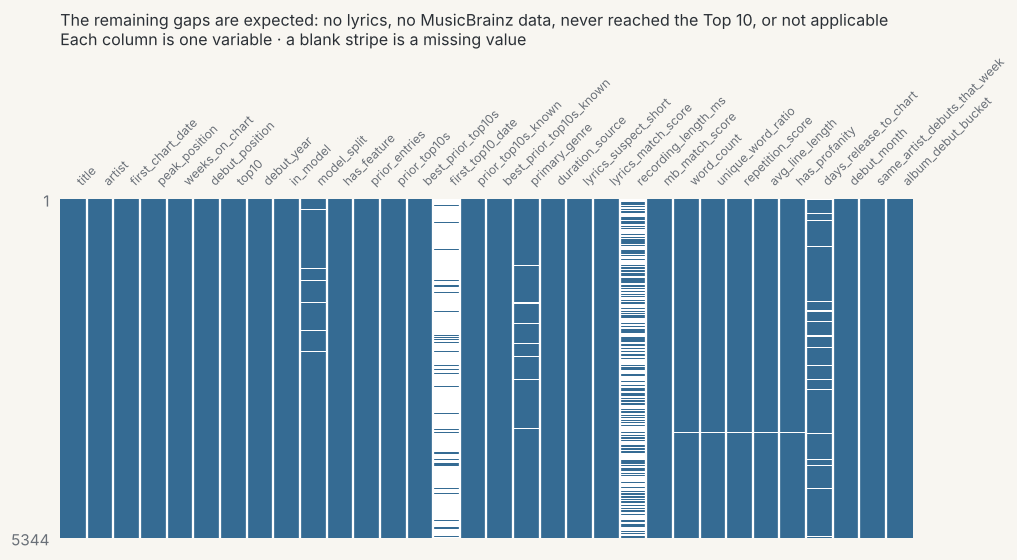

saved data/clean/songs_rebuilt.csv: 5,344 rows x 32 columns


In [19]:
# Step 11a: keep the analysis columns, check what is still missing, and save.
import os
import missingno as msno
import matplotlib.pyplot as plt

KEEP = ["title", "artist", "first_chart_date", "peak_position", "weeks_on_chart", "debut_position", "top10",
        "debut_year", "in_model", "model_split", "has_feature", "prior_entries", "prior_top10s", "best_prior_top10s",
        "first_top10_date", "prior_top10s_known", "best_prior_top10s_known",
        "primary_genre", "duration_source", "lyrics_suspect_short", "lyrics_match_score", "recording_length_ms",
        "mb_match_score", "word_count", "unique_word_ratio", "repetition_score", "avg_line_length", "has_profanity",
        "days_release_to_chart", "debut_month", "same_artist_debuts_that_week", "album_debut_bucket"]
df_clean = df_clean[KEEP]

print(df_clean.isna().sum()[df_clean.isna().sum() > 0])
msno.matrix(df_clean, figsize=(10, 4), fontsize=8, sparkline=False,
            color=(0.21, 0.42, 0.58))           # slate = value present, blank = missing
plt.title("The remaining gaps are expected: no lyrics, no MusicBrainz data, never reached the Top 10, or not applicable\n"
          "Each column is one variable · a blank stripe is a missing value", loc="left", fontsize=10.5)
plt.show()

os.makedirs("data/clean", exist_ok=True)
df_clean.to_csv("data/clean/songs_rebuilt.csv", index=False)
print(f"saved data/clean/songs_rebuilt.csv: {len(df_clean):,} rows x {len(df_clean.columns)} columns")

In [20]:
# Step 11b: compare with songs_analysis.csv. Both files are read back from CSV and matched on title + artist.
rebuilt = pd.read_csv("data/clean/songs_rebuilt.csv")
original = pd.read_csv("data/clean/songs_analysis.csv")
both = original.merge(rebuilt, on=["title", "artist"], how="inner", suffixes=("_orig", "_new"))
print(f"songs: original {len(original):,} | rebuilt {len(rebuilt):,} | matched on title + artist {len(both):,}\n")

match = {}
for col in [c for c in KEEP[2:] if c in original.columns]:      # the strict history columns are new, so not compared
    a, b = both[col + "_orig"], both[col + "_new"]
    if a.dtype in ["int64", "float64"] and b.dtype in ["int64", "float64"]:
        same = ((a - b).abs() < 0.01) | (a.isna() & b.isna())     # numbers: equal to 2 decimals
    else:
        same = a.fillna("blank").astype(str) == b.fillna("blank").astype(str)   # text and True/False: identical
    match[col] = round(same.mean() * 100, 2)
pd.Series(match, name="% of songs that agree").sort_values().to_frame()

songs: original 5,342 | rebuilt 5,344 | matched on title + artist 5,342



,% of songs that agree
primary_genre,98.65
prior_entries,99.44
lyrics_suspect_short,99.74
best_prior_top10s,99.76
prior_top10s,99.79
avg_line_length,99.83
has_profanity,99.85
word_count,99.94
unique_word_ratio,99.96
weeks_on_chart,99.96


**What the comparison shows.** All 5,342 songs in `songs_analysis.csv` are found in the rebuild.
The rebuild has 2 extra rows: two songs whose renamed credits it leaves unmerged. "Bottle
Rockets" switched capitalisation back and forth week to week, and "Ever Since U Left Me" swapped
its lead artist (this also moves peak and weeks for those songs). 14 of the 27 compared columns
agree on every song and the rest agree on at least 98.7%, most above 99.8%. The small gaps come
from three simplifications:

- The protected list of acts is shorter than the one our original scripts learned from the full
  archive, so a few artists' histories differ by an entry or two (99.4–99.8% agreement).
- A genre tie is settled with the artist's main genre rather than only among the tied genres
  (98.7%).
- The truncated-lyrics flag depends on the genre, so a different genre can move a song across
  its genre's 2% line (99.7%).

None of these is large enough to change a headline number. Section 4 keeps reading
`songs_analysis.csv`, the file the findings were computed from.

### Summary: what we changed and why

The table below lists every issue our original scripts fixed. Rows about `plain_lyrics` matching
and the `NaN` bug were fixed while fetching from the APIs, so those fixes are already in the raw
files. The rest are rebuilt in the steps above, some with simpler rules (for example a shorter
protected list of acts).

| Column | Issue | Action | Justification |
|---|---|---|---|
| `artist` | Billboard writes one credit as a single string, and `&` / `,` separators were not being split at all because the regex used `\b&\b`, which can never match — a word boundary needs a word character on one side | Rewrote the splitter; symbol separators dropped the `\b` | Without it, "Bruno Mars & Cardi B" was one unknown artist with no history. Fixing it moved first-time-artist share from 22.7% to 9.7% |
| `artist` | Splitting on `&` / `,` wrongly broke single acts ("Earth, Wind & Fire", "Tyler, The Creator") | 104-name protected list, derived by scanning the archive for credits billed as a recurring unit | A rule cannot tell "Earth, Wind & Fire" from "Future & Metro Boomin"; only recurrence in the data can |
| `artist` | Billboard typos and abbreviations: "Feauring", "Featauring", "Ft.", "W/", "A Duet With" | Added as literal separator spellings | Fuzzy matching was rejected: "wit" (A Boogie Wit da Hoodie) and "fat" (Fat Boys) score highly but are real names |
| `title` + `artist` | The same song listed under two credits when Billboard changed it mid-run ("Kanye West" → "Ye"), splitting its weeks and understating its peak | Merged 69 rows into 34 songs; kept the debut credit as canonical | Peak and weeks were both wrong. "Carnival" was two rows peaking at 1 and 4 |
| `title` | Merging risked collapsing genuinely different recordings | Version-marked parentheticals (a year, "Interlude", "Remix") block a merge | "(1959)" and "(1954)" are two Perry Como recordings, not one song |
| `plain_lyrics` | LRCLIB returned an instrumental upload for songs that plainly have vocals | Prefer a candidate carrying lyrics when scores are close | "Wait For U" had 0 characters of lyrics; it now has 3,188 |
| `plain_lyrics` | Title-only search returned a different act's song of the same name | Require artist similarity ≥ 70 for a title-only match, else unmatched | J. Cole's "close" had been given IZECOLD's lyrics at a "confident" score of 78 |
| `plain_lyrics` | Some uploads are truncated but still match on title and artist | `lyrics_suspect_short` flags the bottom 2% of characters-per-second within each genre | A global cutoff would over-flag country (median 8.0 chars/sec) and under-flag rap (14.9) |
| `duration` | LRCLIB durations were sometimes an album's length (up to 58 minutes) or a 0-2 second placeholder | Fall back to the MusicBrainz recording length | 346 songs had an unusable duration, which made characters-per-second meaningless |
| `genres` | MusicBrainz returns genres alphabetically, not by popularity | Store the vote counts and weight by them | We had assumed rank implied popularity. It does not — that assumption invented a ranking for tied genres |
| `genre_counts`, `recording_mbid` | Read back from CSV as `NaN`, which is truthy in Python, so `value or ""` kept it and `str()` made the non-empty string `"nan"` | One shared `cell_text()` helper treats `"nan"` as empty | Empty cells were being counted as real content; it would also have fired ~250 wasted API requests |
| lyric features | Songs with no lyrics would score 0 on every measure | Left blank, never 0 | A song with no lyrics did not score zero words. Zero is a measurement; blank is the truth |

### Before and after

In [21]:
# The merge of duplicate credits is the one change that alters the row count.
raw_lyrics_rows = 5377          # one row per credit fetched from LRCLIB
merged_songs = len(df)          # one row per song after merging duplicate credits

print("Row counts")
print(f"  credits fetched from LRCLIB      {raw_lyrics_rows:,}")
print(f"  songs after merging duplicates   {merged_songs:,}")
print(f"  rows removed by the merge        {raw_lyrics_rows - merged_songs:,}"
      "   (35 duplicate credits + 0 other)")

print("\nEffect of the merge on the target")
print("  'Carnival' and 'Karma' were each counted as TWO Top 10 songs before merging.")
print(f"  Top 10 count fell 521 -> {df['top10'].sum()} as a result.")

Row counts
  credits fetched from LRCLIB      5,377
  songs after merging duplicates   5,342
  rows removed by the merge        35   (35 duplicate credits + 0 other)

Effect of the merge on the target
  'Carnival' and 'Karma' were each counted as TWO Top 10 songs before merging.
  Top 10 count fell 521 -> 519 as a result.


In [22]:
# Cleaning evidence: match quality, the 'nan' bug, and how many bad durations were repaired.
print("Match quality (share at or above the trusted score of 72)")
for label, col in [("lyrics", "lyrics_match_score"), ("musicbrainz", "mb_match_score")]:
    s = df[col].dropna()
    print(f"  {label:12} {(s >= 72).mean()*100:5.1f}%   n={len(s):,}")

print("\nThe NaN-truthiness bug, demonstrated")
empty = float("nan")
print(f"  bool(float('nan'))            -> {bool(empty)}      <- an empty cell looks True")
print(f"  str(empty or '')              -> {str(empty or '')!r}   <- and becomes non-empty text")
print("  cell_text() fixes this by treating the string 'nan' as empty.")

print("\nDuration repair")
print(df["duration_source"].value_counts().to_string())
print(f"  unusable before the MusicBrainz fallback: 346")
print(f"  unusable after:                           {(df['duration_source'] == 'none').sum()}")

Match quality (share at or above the trusted score of 72)
  lyrics        99.4%   n=5,342
  musicbrainz   99.0%   n=5,342

The NaN-truthiness bug, demonstrated
  bool(float('nan'))            -> True      <- an empty cell looks True
  str(empty or '')              -> 'nan'   <- and becomes non-empty text
  cell_text() fixes this by treating the string 'nan' as empty.

Duration repair
duration_source
lrclib         4960
musicbrainz     308
none             74
  unusable before the MusicBrainz fallback: 346
  unusable after:                           74


In [23]:
# Missing values: songs without lyrics stay blank (not 0), and the remaining gaps are listed.
print("Deliberately blank, not zero")
print(f"  songs with no lyric features : {df['word_count'].isna().sum():>4}"
      "   (31 unmatched + 1 true instrumental)")
print(f"  songs with word_count == 0   : {(df['word_count'] == 0).sum():>4}   <- must be 0")

print("\nRemaining known gaps")
for col, note in [("primary_genre", "no genre in MusicBrainz"),
                  ("days_release_to_chart", "release date is a year only, so no exact day"),
                  ("recording_length_ms", "only fetched where LRCLIB's duration was unusable")]:
    print(f"  {col:24} {df[col].isna().sum():>5} missing  ({df[col].isna().mean()*100:4.1f}%)  {note}")
print(f"  {'lyrics_suspect_short':24} {int(df['lyrics_suspect_short'].sum()):>5} flagged as possibly truncated")

Deliberately blank, not zero
  songs with no lyric features :   32   (31 unmatched + 1 true instrumental)
  songs with word_count == 0   :    0   <- must be 0

Remaining known gaps
  primary_genre              166 missing  ( 3.1%)  no genre in MusicBrainz
  days_release_to_chart      420 missing  ( 7.9%)  release date is a year only, so no exact day
  recording_length_ms       3026 missing  (56.6%)  only fetched where LRCLIB's duration was unusable
  lyrics_suspect_short       109 flagged as possibly truncated


**So what:** three bugs (`\b&\b`, NaN-truthiness, and assuming alphabetical order meant
popularity) each silently corrupted a feature while the code ran without error — the
cleaning that mattered most was the kind that produced no traceback.

## 4. Exploratory questions

Section 4.0 checks the data first. Then come fifteen questions in five themes. Each theme starts
with a main question (Q1-Q5) and adds two follow-ups (a and b) that dig deeper or check whether
the main result survives the most likely confounder. All tests use the 2018-2024 training songs
only. Questions whose answer turned out to be "no detectable difference" were dropped from the main
analysis and are listed in 4.7, so nothing tested is hidden.

| Theme | # | Question | Chart |
|---|---|---|---|
| 4.1 Genre | Q1 | Which genres have the highest share of songs reaching the Top 10? | 1 |
| | Q1a | Do genre differences persist after excluding songs that debuted alongside other songs by the same artist? | 2 |
| | Q1b | Within each genre, how do songs by artists with and without a previous Top 10 compare? | 3 |
| 4.2 Artist track record | Q2 | How does the Top 10 rate change with the number of Top 10 hits the artist had reached before the song's debut? | 4 |
| | Q2a | Among experienced artists, is the share of their earlier songs that reached the Top 10 (hit ratio) associated with success? | 5 |
| | Q2b | Among artists without a previous Top 10, how does the rate vary with the number of earlier chart entries? | 6 |
| 4.3 Artist reach | Q3 | How concentrated are Top 10 songs among a small number of artists? | 7 |
| | Q3a | Do songs by artists from outside the US reach the Top 10 more often than songs by US artists? | 8 |
| | Q3b | Does the origin gap hold among artists with a similar number of previous hits? | 9 |
| 4.4 Release strategy | Q4 | Is the number of songs an artist debuts in the same week associated with Top 10 success? | 10 |
| | Q4a | Do singles and album tracks differ, and does any gap remain among songs debuting alone? | 11 |
| | Q4b | Is the same-week debut pattern found in both hip-hop and pop? | 12 |
| 4.5 Timing and lyrics | Q5 | Does the Top 10 rate differ by chart debut month, and does any difference survive excluding big same-artist debut weeks? | 13 |
| | Q5a | How did the genre make-up of Top 10 songs change, and did any genre's own Top 10 rate change? | 14 |
| | Q5b | Do Top 10 songs differ from other songs on four lyric measures? | 15 |

#### How each question is laid out

1. Research question: what is being compared, and the hypothesis.
2. Data analysis: the Top 10 rate and sample size for each group, and the statistical test.
3. Visualization: a chart whose headline states the result, with percentages and sample sizes.
4. Finding: one or two sentences with the actual numbers.
5. Interpretation: what the result suggests, without claiming causation or overstating significance.

#### Terms used throughout

- Previous Top 10: the lead artist had reached the Top 10 with an earlier song before this song's debut week (4.0c explains why "before the debut" matters).
- Hit ratio: the share of the lead artist's earlier Hot 100 entries that had reached the Top 10 by this song's debut.
- Only debut that week (or "debuting alone"): no other song by the same lead artist entered the Hot 100 in the same week.
- Origin: the lead artist's country as recorded in MusicBrainz.
- Top 10 rate: the share of songs in a group that ever reached positions 1-10.

#### Tests used

Chi-square compares Top 10 rates across groups, with Cramér's V as the effect size. Mann-Whitney U
compares a number, such as word count, between Top 10 songs and the rest, with the rank-biserial r
as the effect size. With about 4,300 songs almost anything can reach significance, so the effect
size says whether a difference is large enough to matter. Significance is read at α = 0.05.

#### How to read the results

- Null hypothesis (H₀): the default, "this factor makes no difference". We only claim a difference when the data make that default very unlikely.
- p-value: how surprising the result would be if the factor truly made no difference. Below 0.05, we treat the difference as real.
- Cramér's V (0 to 1) and rank-biserial r (-1 to 1): how big the effect is. Under 0.1 in size is negligible, 0.1 to 0.3 is small.
- A non-significant result is not proof of no difference, only a lack of evidence for one.
- Every result is an association. Nothing here was randomised, so none of it shows cause and effect.

In [24]:
# Helper functions reused by every question:
#   chi_square()   compares Top 10 rates across groups and measures the effect size (Cramér's V)
#   report()       prints the test result and the table of rates
#   mann_whitney() compares a number (e.g. word count) between Top 10 songs and the rest, with an effect size
#   top10_rates()  songs, Top 10 count and Top 10 rate per group (used by the charts)
ALPHA = 0.05

def chi_square(data, column, target="top10"):
    """Chi-square with Cramer's V, plus the Top 10 rate in each group."""
    table = pd.crosstab(data[column], data[target])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rates = (table[True] / table.sum(axis=1) * 100).round(1)
    summary = pd.DataFrame({"songs": table.sum(axis=1), "top10": table[True], "top10_rate_pct": rates})
    return {"chi2": chi2, "p": p, "dof": dof, "v": v, "summary": summary}

def report(result, name):
    verdict = "REJECT the null" if result["p"] < ALPHA else "cannot reject the null"
    strength = ("negligible" if result["v"] < 0.1 else "small" if result["v"] < 0.3 else
                "moderate" if result["v"] < 0.5 else "large")
    print(f"{name}\n" + "-" * len(name))
    print(f"  chi2({result['dof']}) = {result['chi2']:.1f}   p = {result['p']:.3g}   "
          f"Cramer's V = {result['v']:.3f} ({strength})")
    print(f"  -> {verdict} at alpha = {ALPHA}\n")
    display(result["summary"])

def mann_whitney(data, column, target="top10"):
    """Mann-Whitney U test plus the rank-biserial effect size r (-1 to 1; 0 = no difference;
    positive = Top 10 songs tend to score higher)."""
    a = data.loc[data[target], column].dropna()
    b = data.loc[~data[target], column].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1
    return {"u": u, "p": p, "effect_r": r, "median_top10": a.median(), "median_other": b.median(),
            "n_top10": len(a), "n_other": len(b)}

def top10_rates(data, by):
    """Songs, Top 10 count and Top 10 rate (%) per group."""
    return (data.groupby(by, observed=True)["top10"]
                .agg(songs="size", top10="sum")
                .assign(top10_rate_pct=lambda t: (t["top10"] / t["songs"] * 100).round(1)))

### 4.0 Checks before the analysis

Three checks come before any question: (a) the sample totals in the notebook match the CSV, and each
question's base is stated; (b) missing values are counted and handled explicitly; (c) the artist-history
measures only use information available before each song's debut.

In [25]:
# 4.0a: add the strict artist-history columns from Step 5c, then reconcile the sample totals.
strict = pd.read_csv("data/clean/songs_rebuilt.csv", parse_dates=["first_top10_date"],
                     usecols=["title", "artist", "first_top10_date", "prior_top10s_known", "best_prior_top10s_known"])
df = df.merge(strict, on=["title", "artist"], how="left", validate="one_to_one")
df["first_chart_date"] = pd.to_datetime(df["first_chart_date"])
print("songs in the CSV without a strict history value:", df["prior_top10s_known"].isna().sum())

# Re-create the three groups from Section 1 so they carry the new columns.
train = df[df["model_split"] == "train"].copy()
test = df[df["model_split"] == "test"].copy()
excluded = df[~df["in_model"]]

totals = pd.DataFrame({
    "songs": [len(df), len(train), len(test), len(excluded), len(train) + len(test) + len(excluded)],
    "top10": [df["top10"].sum(), train["top10"].sum(), test["top10"].sum(), excluded["top10"].sum(),
              train["top10"].sum() + test["top10"].sum() + excluded["top10"].sum()]},
    index=["songs_analysis.csv (all songs)", "train: debuted 2018-2024", "test: debuted 2025-2026 (held out)",
           "still charting (no final peak)", "train + test + still charting"])
totals["top10_rate_pct"] = (totals["top10"] / totals["songs"] * 100).round(1)
display(totals)
print("rebuilt file from Section 3:", len(pd.read_csv("data/clean/songs_rebuilt.csv")),
      "rows (the 2 extra rows are the two unmerged renamed credits noted in Step 11)")

# The base each question works from (training songs only).
bases = pd.Series({
    "all training songs (Q2, Q3, Q4, Q5)": len(train),
    "with a genre (Q1, Q1b, Q5a)": train["primary_genre"].notna().sum(),
    "with a genre and debuting alone (Q1a)": (train["primary_genre"].notna() & (train["album_debut_bucket"] == "1")).sum(),
    "no previous Top 10 (Q2b)": (train["prior_top10s_known"] == 0).sum(),
    "single, album or EP release (Q4a)": train["release_type"].isin(["Single", "Album", "EP"]).sum(),
    "with lyrics (Q5b)": train["word_count"].notna().sum(),
    "lead artist with 3+ earlier entries (Q2a)": (train["prior_entries"] >= 3).sum(),
    "hip-hop or pop (Q4b)": train["primary_genre"].isin(["hip-hop/rap", "pop"]).sum(),
    "Top 10 songs (Q3, Q5a)": train["top10"].sum()}, name="songs")
display(bases.to_frame())

songs in the CSV without a strict history value: 0


,songs,top10,top10_rate_pct
songs_analysis.csv (all songs),5342,519,9.7
train: debuted 2018-2024,4293,441,10.3
test: debuted 2025-2026 (held out),950,56,5.9
still charting (no final peak),99,22,22.2
train + test + still charting,5342,519,9.7


rebuilt file from Section 3: 5344 rows (the 2 extra rows are the two unmerged renamed credits noted in Step 11)


,songs
"all training songs (Q2, Q3, Q4, Q5)",4293
"with a genre (Q1, Q1b, Q5a)",4176
with a genre and debuting alone (Q1a),2031
no previous Top 10 (Q2b),1527
"single, album or EP release (Q4a)",4184
with lyrics (Q5b),4274
lead artist with 3+ earlier entries (Q2a),3494
hip-hop or pop (Q4b),2813
"Top 10 songs (Q3, Q5a)",441


In [26]:
# 4.0b: missing values in the columns Section 4 uses (training songs), and how each is handled.
used = {"primary_genre": "left out of genre questions",
        "release_type": "left out of Q4a (with the 109 songs of other release types)",
        "word_count": "no lyrics: left out of lyric questions, never counted as 0",
        "unique_word_ratio": "as word_count",
        "has_profanity": "as word_count",
        "artist_mbids": "no MusicBrainz artist: origin unknown, left out of Q3a and Q3b",
        "first_top10_date": "blank for songs that never reached the Top 10 (expected)",
        "prior_top10s_known": "must be 0 missing"}
missing_table = pd.DataFrame({"missing": train[list(used)].isna().sum(),
                              "pct_of_train": (train[list(used)].isna().mean() * 100).round(1),
                              "handling": pd.Series(used)})
display(missing_table)
consistent = (train["first_top10_date"].isna() == ~train["top10"]).mean() * 100
print(f"first_top10_date is blank exactly when the song never reached the Top 10: {consistent:.1f}% of songs")

,missing,pct_of_train,handling
primary_genre,117,2.7,left out of genre questions
release_type,58,1.4,left out of Q4a (with the 109 songs of other r...
word_count,19,0.4,"no lyrics: left out of lyric questions, never ..."
unique_word_ratio,19,0.4,as word_count
has_profanity,19,0.4,as word_count
artist_mbids,47,1.1,"no MusicBrainz artist: origin unknown, left ou..."
first_top10_date,3852,89.7,blank for songs that never reached the Top 10 ...
prior_top10s_known,0,0.0,must be 0 missing


first_top10_date is blank exactly when the song never reached the Top 10: 100.0% of songs


In [27]:
# 4.0c: do the artist-history counts only use information available at debut?
# prior_top10s (from the original pipeline) counts every earlier song that EVENTUALLY reached the Top 10,
# even if it got there after this song debuted. prior_top10s_known counts only songs that had already
# reached the Top 10 before this song's debut week.
changed = train["prior_top10s"] != train["prior_top10s_known"]
print(f"training songs where the two counts differ: {changed.sum()} of {len(train):,} ({changed.mean():.1%})")
print(f"  of which the strict count is lower: {(train['prior_top10s_known'] < train['prior_top10s']).sum()}")

buckets = [-1, 0, 4, 9, np.inf]
names = ["0", "1-4", "5-9", "10+"]
side_by_side = pd.concat({
    "eventual hits (original)": top10_rates(train, pd.cut(train["prior_top10s"], buckets, labels=names)),
    "hits known at debut (used below)": top10_rates(train, pd.cut(train["prior_top10s_known"], buckets, labels=names))},
    axis=1)
display(side_by_side)

# Use the strict version everywhere in Section 4.
train["prior_hits"] = train["prior_top10s_known"]
train["best_prior_hits"] = train["best_prior_top10s_known"]
train["artist_status"] = np.where(train["prior_hits"] > 0, "Previous Top 10", "No previous Top 10")
STATUS_ORDER = ["No previous Top 10", "Previous Top 10"]
print(train["artist_status"].value_counts().reindex(STATUS_ORDER))

training songs where the two counts differ: 404 of 4,293 (9.4%)
  of which the strict count is lower: 400


eventual hits (original)                      hits known at debut (used below)                     
                       songs top10 top10_rate_pct                            songs top10 top10_rate_pct
0                       1476    85            5.8                             1527    89            5.8
1-4                     1452   127            8.7                             1413   125            8.8
5-9                      458    61           13.3                              456    61           13.4
10+                      907   168           18.5                              897   166           18.5

artist_status
No previous Top 10    1527
Previous Top 10       2766
Name: count, dtype: int64


**What the checks show.** The CSV's 5,342 songs split exactly into 4,293 training songs, 950 held-out
test songs and 99 still charting. The rebuilt file from Section 3 has 2 extra rows (the two unmerged
renamed credits noted in Step 11) and is used here only for the strict history columns. Missing values
are small except release dates (9.2% of training songs), and each question works from the base listed
above.

The original count of previous Top 10s included songs that reached the Top 10 only after the song being
analysed had debuted. That affects 404 training songs (9.4%), almost always by one hit. Section 4 uses the
strict count, which only includes hits already reached at debut. It changes the Q2 rates by at most 0.1
points, so the earlier findings stand, but now every artist-history measure is knowable at debut.

### 4.1 Genre

Q1 compares genres. Q1a checks whether the gaps come from some genres debuting more songs at once, and
Q1b compares artists with and without a previous hit inside each genre.

#### Q1. Which genres have the highest share of songs reaching the Top 10?

**Research question.** We compare the Top 10 rate across the nine broad genres, using the 4,176 training
songs that have a genre label.

**Hypothesis.** H₀: the Top 10 rate is the same in every genre. H₁: it differs.

In [28]:
# Q1 test: compare Top 10 rates across genres (songs with a genre label).
q1 = chi_square(train, "primary_genre")
report(q1, "Q1: Top 10 rate by primary genre")
print("songs without a genre (left out):", train["primary_genre"].isna().sum())

Q1: Top 10 rate by primary genre
--------------------------------
  chi2(8) = 89.0   p = 7.35e-16   Cramer's V = 0.146 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
primary_genre,,,
Latin,158,11,7.0
R&B,321,30,9.3
country,510,27,5.3
dance/electronic,106,17,16.0
hip-hop/rap,2017,178,8.8
mixed,64,3,4.7
other,110,8,7.3
pop,796,149,18.7
rock/alternative,94,13,13.8


songs without a genre (left out): 117


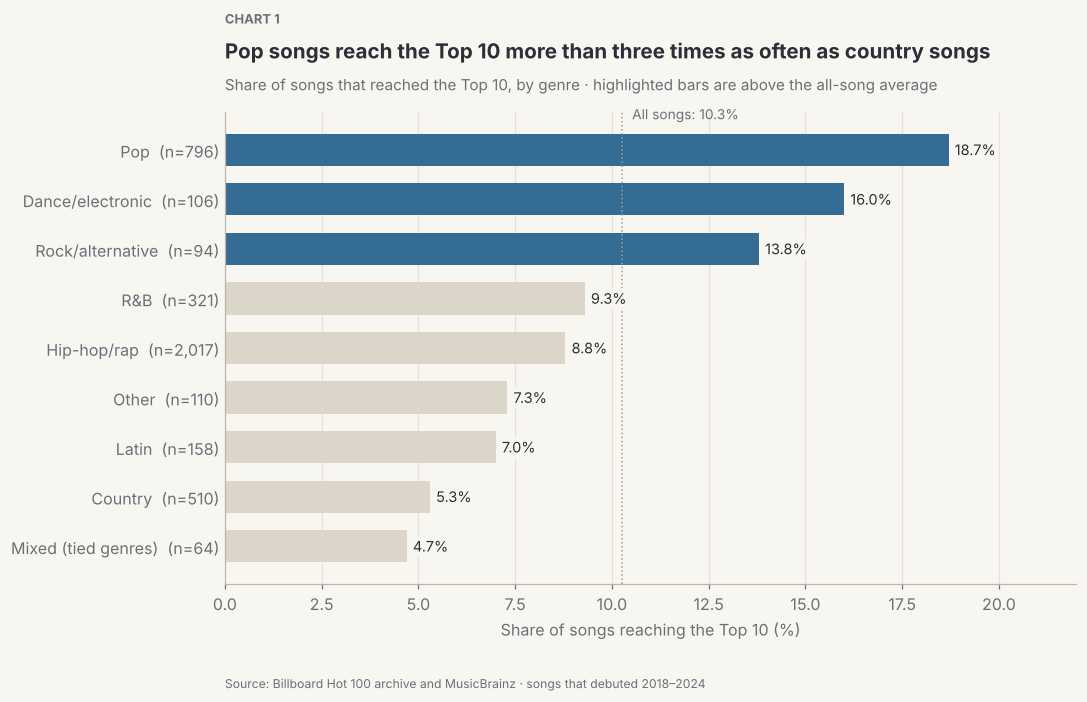

In [29]:
# Chart 1 — Top 10 rate by genre: sorted horizontal bars, above-average genres in slate.
data = q1["summary"].sort_values("top10_rate_pct")          # already aggregated in Q1
overall = train["top10"].mean() * 100
labels = [f"{GENRE_NAMES[g]}  (n={n:,})" for g, n in zip(data.index, data["songs"])]
colours = [FOCUS if r > overall else CONTEXT for r in data["top10_rate_pct"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(labels, data["top10_rate_pct"], color=colours, height=0.65)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9.5,
             bbox=dict(facecolor=BACKGROUND, edgecolor="none", pad=1))     # background box keeps labels readable over the line
ax.axvline(overall, color=REF, linewidth=1, linestyle=":", zorder=1)
ax.text(overall + 0.25, len(data) - 0.45, f"All songs: {overall:.1f}%", fontsize=9, color=MUTED, va="bottom")

ax.set_xlabel("Share of songs reaching the Top 10 (%)")
ax.set_xlim(0, 22)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
ax.set_axisbelow(True)
chart_titles(ax, 1, "Pop songs reach the Top 10 more than three times as often as country songs",
             "Share of songs that reached the Top 10, by genre · highlighted bars are above the all-song average")
show_chart(fig)

**Finding.** Pop has the highest Top 10 rate (18.7% of 796 songs) and country one of the lowest (5.3% of
510), against 10.3% overall. Genre and Top 10 status are associated (χ²(8) = 89.0, p < 0.001), with a small
effect size (V = 0.146).

**Interpretation.** Pop songs reach the Top 10 about 3.5 times as often as country songs, so genre shifts
the odds without deciding them. Genre also travels with who releases a song and how, which Q1a and Q1b
look at. Labels come from MusicBrainz volunteers; the 117 training songs without a genre are left out, and
the 64 "mixed" songs are ties between two genres.

#### Q1a. Do genre differences persist after excluding songs that debuted alongside other songs by the same artist?

**Research question.** We compare each genre's Top 10 rate for all songs with its rate among songs that
were the artist's only Hot 100 debut that week (2,031 songs with a genre). Q4 shows that songs debuting
alongside several others reach the Top 10 less often, and some genres do that far more than others.

**Hypothesis.** H₀: among songs debuting alone, the Top 10 rate is the same in every genre. H₁: it still
differs.

In [30]:
# Q1a test: repeat Q1 using only songs that were the artist's only chart debut that week.
alone = train[train["album_debut_bucket"] == "1"]
multi = train["album_debut_bucket"] != "1"
print("Share of each genre's songs that debuted alongside other songs by the same artist (%)")
display(multi.groupby(train["primary_genre"]).mean().mul(100).round(1)
             .sort_values(ascending=False).rename("pct_multi_debut").to_frame().T)

q1a = chi_square(alone, "primary_genre")
report(q1a, "Q1a: Top 10 rate by genre, excluding same-week multi-song debuts")

Share of each genre's songs that debuted alongside other songs by the same artist (%)


primary_genre,hip-hop/rap,R&B,Latin,pop,rock/alternative,mixed,country,dance/electronic,other
pct_multi_debut,66.3,59.2,41.8,37.6,31.9,29.7,28.4,28.3,25.5


Q1a: Top 10 rate by genre, excluding same-week multi-song debuts
----------------------------------------------------------------
  chi2(8) = 63.4   p = 1.02e-10   Cramer's V = 0.177 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
primary_genre,,,
Latin,92,5,5.4
R&B,131,17,13.0
country,365,17,4.7
dance/electronic,76,13,17.1
hip-hop/rap,679,74,10.9
mixed,45,3,6.7
other,82,8,9.8
pop,497,103,20.7
rock/alternative,64,5,7.8


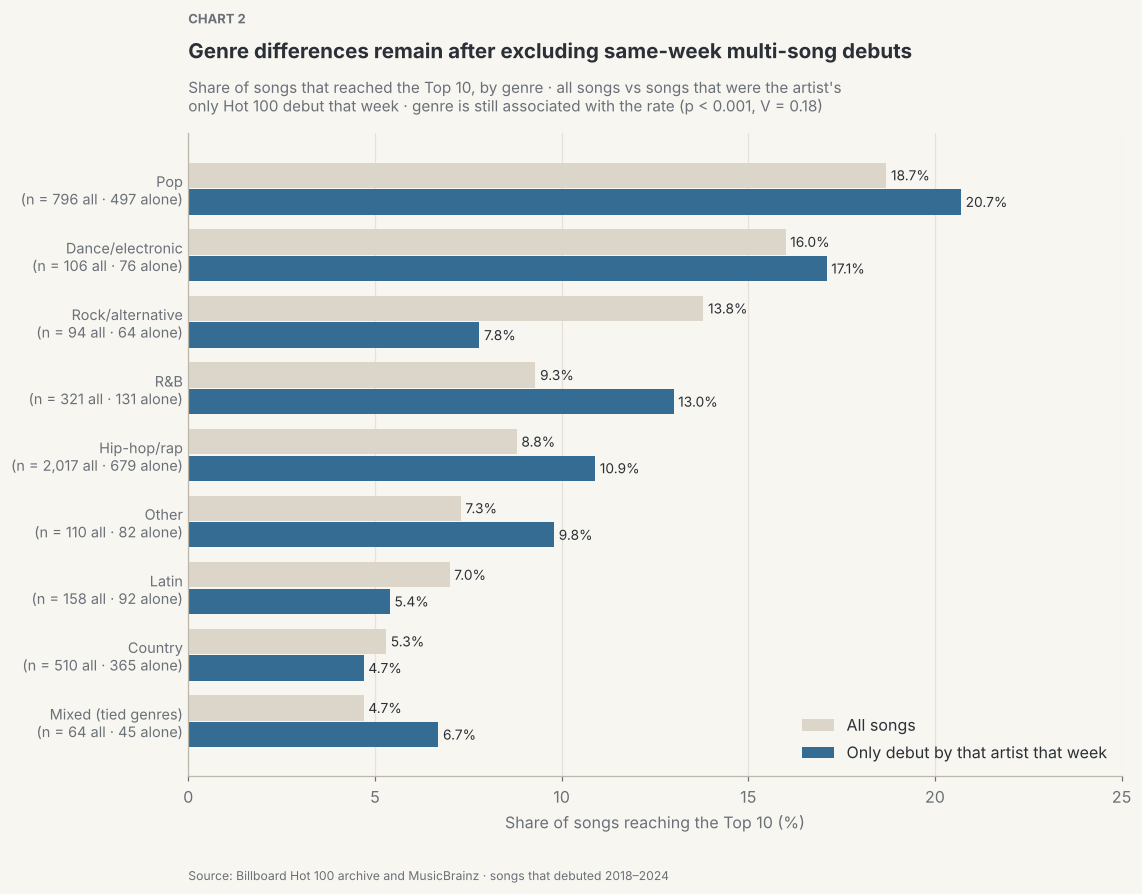

In [31]:
# Chart 2 — Top 10 rate by genre: all songs vs songs that were the artist's only debut that week.
genre_order = q1["summary"].sort_values("top10_rate_pct", ascending=False).index     # same order as Chart 1
all_rates = top10_rates(train, "primary_genre").loc[genre_order]
alone_rates = top10_rates(alone, "primary_genre").loc[genre_order]

y = np.arange(len(genre_order))
fig, ax = plt.subplots(figsize=(10.5, 7))
bars_all = ax.barh(y - 0.2, all_rates["top10_rate_pct"], height=0.38, color=CONTEXT, label="All songs")
bars_alone = ax.barh(y + 0.2, alone_rates["top10_rate_pct"], height=0.38, color=FOCUS,
                     label="Only debut by that artist that week")
for bars in (bars_all, bars_alone):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_yticks(y, [f"{GENRE_NAMES[g]}\n(n = {a:,} all · {b:,} alone)"
                  for g, a, b in zip(genre_order, all_rates["songs"], alone_rates["songs"])], fontsize=9.5)
ax.invert_yaxis()                                     # highest overall rate at the top, as in Chart 1
ax.set_xlabel("Share of songs reaching the Top 10 (%)")
ax.set_xlim(0, 25)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.legend(loc="lower right")
chart_titles(ax, 2, "Genre differences remain after excluding same-week multi-song debuts",
             "Share of songs that reached the Top 10, by genre · all songs vs songs that were the artist's\n"
             f"only Hot 100 debut that week · genre is still associated with the rate (p < 0.001, V = {q1a['v']:.2f})")
show_chart(fig)

**Finding.** Among songs debuting alone, genre is still associated with the Top 10 rate (χ²(8) = 63.4,
p < 0.001, V = 0.177): pop 20.7% against country 4.7%. Hip-hop (66.3%) and R&B (59.2%) have the largest
shares of songs debuting alongside others, and their rates rise most when those songs are excluded
(8.8% to 10.9% and 9.3% to 13.0%).

**Interpretation.** Same-week multi-song debuts account for part of hip-hop's and R&B's lower overall rates,
but not for the genre gap as a whole. Small genres rest on very few hits once filtered (5 each for Latin and
rock/alternative), so only the large genres should be read closely. Rock/alternative falls from 13.8% to
7.8%, which suggests a few multi-song weeks lifted its overall figure.

#### Q1b. Within each genre, how do songs by artists with and without a previous Top 10 compare?

**Research question.** Inside each genre, we compare the Top 10 rate of songs whose lead artist had a
previous Top 10 at debut with songs whose lead artist had none. The chart shows the five genres with at
least 50 songs in both groups.

**Hypothesis.** H₀: within a genre, the Top 10 rate is the same for both groups. H₁: it differs.

In [32]:
# Q1b test: within each genre, compare artists with and without a previous Top 10.
rows = []
for genre, g in train.dropna(subset=["primary_genre"]).groupby("primary_genre"):
    without, with_hit = g[g["artist_status"] == "No previous Top 10"], g[g["artist_status"] == "Previous Top 10"]
    result = chi_square(g, "artist_status")
    rows.append({"genre": genre, "n_without": len(without), "n_with": len(with_hit),
                 "rate_without": round(without["top10"].mean() * 100, 1),
                 "rate_with": round(with_hit["top10"].mean() * 100, 1),
                 "gap_pts": round((with_hit["top10"].mean() - without["top10"].mean()) * 100, 1),
                 "p_value": round(result["p"], 4)})
q1b = pd.DataFrame(rows).set_index("genre").sort_values("n_without", ascending=False)
display(q1b)

# Overall, for reference.
report(chi_square(train, "artist_status"), "All genres: previous Top 10 vs none")

,n_without,n_with,rate_without,rate_with,gap_pts,p_value
genre,,,,,,
hip-hop/rap,539,1478,3.9,10.6,6.7,0.0000
country,296,214,3.0,8.4,5.4,0.0134
pop,223,573,16.6,19.5,3.0,0.3906
R&B,141,180,5.0,12.8,7.8,0.0283
Latin,86,72,3.5,11.1,7.6,0.1185
other,65,45,6.2,8.9,2.7,0.8652
dance/electronic,34,72,11.8,18.1,6.3,0.5890
mixed,31,33,6.5,3.0,-3.4,0.9558
rock/alternative,23,71,4.3,16.9,12.6,0.2427


All genres: previous Top 10 vs none
-----------------------------------
  chi2(1) = 50.0   p = 1.51e-12   Cramer's V = 0.108 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
artist_status,,,
No previous Top 10,1527,89,5.8
Previous Top 10,2766,352,12.7


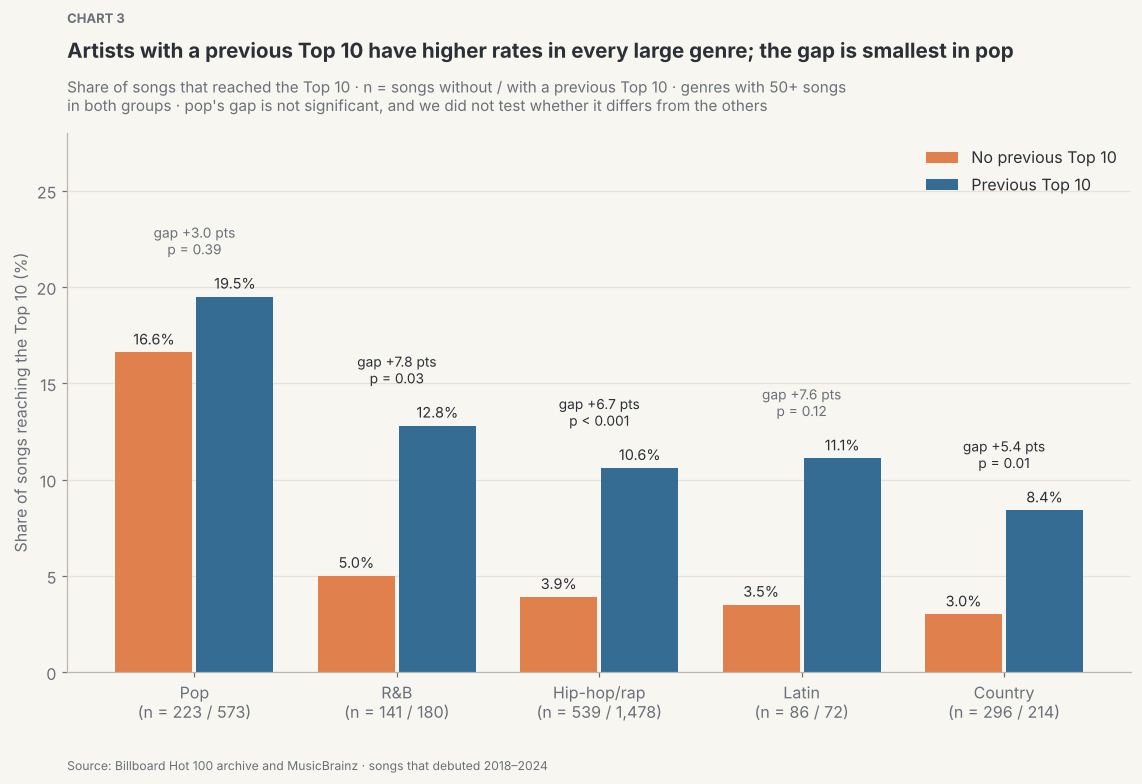

In [33]:
# Chart 3 — grouped bars: Top 10 rate for artists with and without a previous Top 10, by genre.
chart1_order = q1["summary"].sort_values("top10_rate_pct", ascending=False).index     # same genre order as Chart 1
shown = q1b.loc[[g for g in chart1_order if q1b.loc[g, "n_without"] >= 50 and q1b.loc[g, "n_with"] >= 50]]
x = np.arange(len(shown))

fig, ax = plt.subplots(figsize=(10.5, 6))
bars_without = ax.bar(x - 0.2, shown["rate_without"], width=0.38, color=SECOND, label="No previous Top 10")
bars_with = ax.bar(x + 0.2, shown["rate_with"], width=0.38, color=FOCUS, label="Previous Top 10")
for bars in (bars_without, bars_with):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9.5)
for i, (gap_value, p) in enumerate(zip(shown["gap_pts"], shown["p_value"])):
    ax.text(i, max(shown["rate_with"].iloc[i], shown["rate_without"].iloc[i]) + 2.2,
            f"gap {gap_value:+.1f} pts\n" + ("p < 0.001" if p < 0.001 else f"p = {p:.2f}"),
            ha="center", fontsize=9, color=TEXT if p < ALPHA else MUTED)
ax.set_xticks(x, [f"{GENRE_NAMES[g]}\n(n = {a:,} / {b:,})" for g, a, b in
                  zip(shown.index, shown["n_without"], shown["n_with"])])
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 28)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="upper right")
chart_titles(ax, 3, "Artists with a previous Top 10 have higher rates in every large genre; the gap is smallest in pop",
             "Share of songs that reached the Top 10 · n = songs without / with a previous Top 10 · genres with 50+ songs\n"
             "in both groups · pop's gap is not significant, and we did not test whether it differs from the others")
show_chart(fig)

**Finding.** Songs by artists with a previous Top 10 have higher rates in all five large genres. The gap is
significant in hip-hop (3.9% vs 10.6%, p < 0.001), country (3.0% vs 8.4%, p = 0.013) and R&B (5.0% vs
12.8%, p = 0.028), but not in pop (16.6% vs 19.5%, p = 0.39) or Latin (3.5% vs 11.1%, p = 0.12, with only
86 and 72 songs).

**Interpretation.** Pop is the one large genre where songs by artists without a previous hit reach the Top
10 at a rate close to those with one. That is worth noting, but it does not show pop is easier to break
into: a non-significant gap is not evidence of no gap, and we have not tested whether pop's gap is
significantly smaller than the other genres' (that needs a model with a genre-by-history interaction).
We also cannot see label or marketing support behind each song.

**Theme takeaway:** genre is associated with Top 10 rates even after excluding same-week multi-song debuts
(Q1a). Artists with a previous hit have higher rates in every large genre; the gap is smallest in pop, but
we have not shown that pop's gap is genuinely different (Q1b).

### 4.2 Artist track record

Q2 relates an artist's previous hits to the next song's chances. Q2a asks whether the artist's hit
ratio adds information, and Q2b looks inside the group with no previous hit. All counts use only hits
reached before each song's debut (4.0c).

#### Q2. How does the Top 10 rate change with the number of Top 10 hits the artist had reached before the song's debut?

**Research question.** We compare the Top 10 rate across four groups of lead artists: no previous Top 10,
1-4, 5-9, and 10 or more. A previous song only counts if it had reached the Top 10 before this song's
debut week (all 4,293 training songs).

**Hypothesis.** H₀: the number of previous hits is unrelated to reaching the Top 10. H₁: artists with more
previous hits have higher rates.

In [34]:
# Q2 test: Top 10 rate by the lead artist's Top 10 hits reached BEFORE this song's debut (0, 1-4, 5-9, 10+).
train["prior_hit_group"] = pd.cut(train["prior_hits"], [-1, 0, 4, 9, np.inf], labels=["0", "1-4", "5-9", "10+"])
q2 = chi_square(train, "prior_hit_group")
report(q2, "Q2: Top 10 rate by previous Top 10 hits (known at debut)")

Q2: Top 10 rate by previous Top 10 hits (known at debut)
--------------------------------------------------------
  chi2(3) = 106.6   p = 5.98e-23   Cramer's V = 0.158 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
prior_hit_group,,,
0,1527,89,5.8
1-4,1413,125,8.8
5-9,456,61,13.4
10+,897,166,18.5


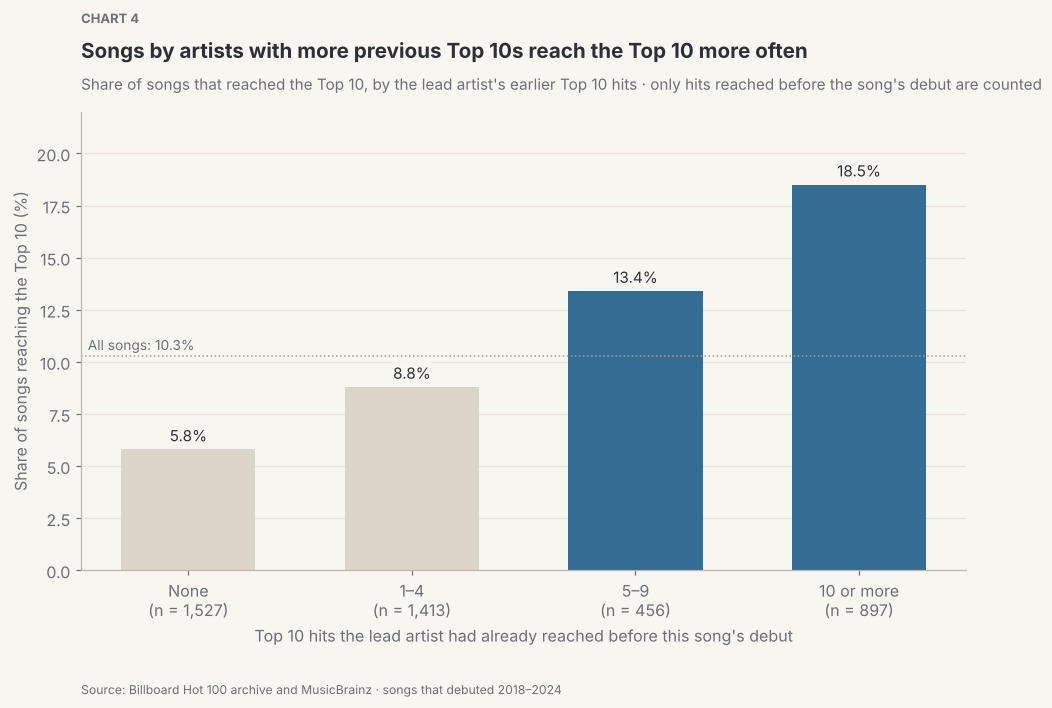

In [35]:
# Chart 4 — Top 10 rate by the lead artist's Top 10 hits reached before this song debuted.
data = q2["summary"]
overall = train["top10"].mean() * 100
names = {"0": "None", "1-4": "1–4", "5-9": "5–9", "10+": "10 or more"}
labels = [f"{names[str(b)]}\n(n = {n:,})" for b, n in zip(data.index, data["songs"])]
colours = [FOCUS if r > overall else CONTEXT for r in data["top10_rate_pct"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels, data["top10_rate_pct"], color=colours, width=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10, bbox=dict(facecolor=BACKGROUND, edgecolor="none", pad=1))
ax.axhline(overall, color=REF, linewidth=1, linestyle=":", zorder=1)
ax.text(-0.45, overall + 0.3, f"All songs: {overall:.1f}%", fontsize=9, color=MUTED)

ax.set_xlabel("Top 10 hits the lead artist had already reached before this song's debut")
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 22)
ax.grid(axis="y")
ax.set_axisbelow(True)
chart_titles(ax, 4, "Songs by artists with more previous Top 10s reach the Top 10 more often",
             "Share of songs that reached the Top 10, by the lead artist's earlier Top 10 hits · "
             "only hits reached before the song's debut are counted")
show_chart(fig)

**Finding.** The Top 10 rate rises steadily with previous hits: 5.8% for artists with none (1,527 songs), 8.8%
for 1-4, 13.4% for 5-9 and 18.5% for 10 or more (χ²(3) = 106.6, p < 0.001, V = 0.158).

**Interpretation.** Songs by artists with ten or more previous hits reach the Top 10 about three times as
often as songs by artists with none. This describes artists rather than songs, and it is partly
self-reinforcing: established artists also get more playlist placement and marketing, which we cannot see.
Counting only hits reached before the debut changes 9.4% of the counts but barely moves these rates (4.0c).

#### Q2a. Among experienced artists, is the share of their earlier songs that reached the Top 10 (hit ratio) associated with success?

**Research question.** For songs whose lead artist had at least 3 earlier Hot 100 entries (3,494 songs), we
compare Top 10 rates across four hit-ratio groups: 0%, 1-10%, 11-25% and over 25% of earlier entries having
reached the Top 10 before this song's debut. We then repeat the comparison within artists who have the same
number of previous hits, to see whether the ratio says more than the count.

**Hypothesis.** H₀: the Top 10 rate is the same in every hit-ratio group. H₁: artists with a higher hit ratio
have higher rates.

In [36]:
# Q2a test: among lead artists with at least 3 earlier chart entries, compare Top 10 rates by hit ratio,
# the share of those earlier entries that had reached the Top 10 before this song's debut.
experienced = train[train["prior_entries"] >= 3].copy()
experienced["hit_ratio"] = (experienced["prior_hits"] / experienced["prior_entries"]).clip(upper=1)
experienced["hit_ratio_group"] = pd.cut(experienced["hit_ratio"], [-0.01, 0, 0.10, 0.25, 1.0],
                                        labels=["0%", "1–10%", "11–25%", "Over 25%"])
q2a = chi_square(experienced, "hit_ratio_group")
report(q2a, "Q2a: Top 10 rate by hit ratio (artists with 3+ earlier entries)")

# Does hit ratio still separate artists who have the same NUMBER of previous hits?
experienced["prior_hit_group"] = pd.cut(experienced["prior_hits"], [-1, 0, 4, 9, np.inf], labels=["0", "1-4", "5-9", "10+"])
rows = []
for group, g in experienced[experienced["prior_hits"] > 0].groupby("prior_hit_group", observed=True):
    r = chi_square(g, "hit_ratio_group")
    rates = r["summary"]["top10_rate_pct"]
    rows.append({"previous_hits": group, "songs": len(g), **{f"rate_{k}": v for k, v in rates.items()},
                 "p_value": round(r["p"], 4)})
q2a_within = pd.DataFrame(rows).set_index("previous_hits")
display(q2a_within)

Q2a: Top 10 rate by hit ratio (artists with 3+ earlier entries)
---------------------------------------------------------------
  chi2(3) = 96.6   p = 8.42e-21   Cramer's V = 0.166 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
hit_ratio_group,,,
0%,786,29,3.7
1–10%,868,61,7.0
11–25%,1313,203,15.5
Over 25%,527,82,15.6


,songs,rate_1–10%,rate_11–25%,rate_Over 25%,p_value
previous_hits,,,,,
1-4,1355,6.7,9.6,14.2,0.0034
5-9,456,6.2,16.1,13.2,0.0778
10+,897,10.7,19.3,19.1,0.1885


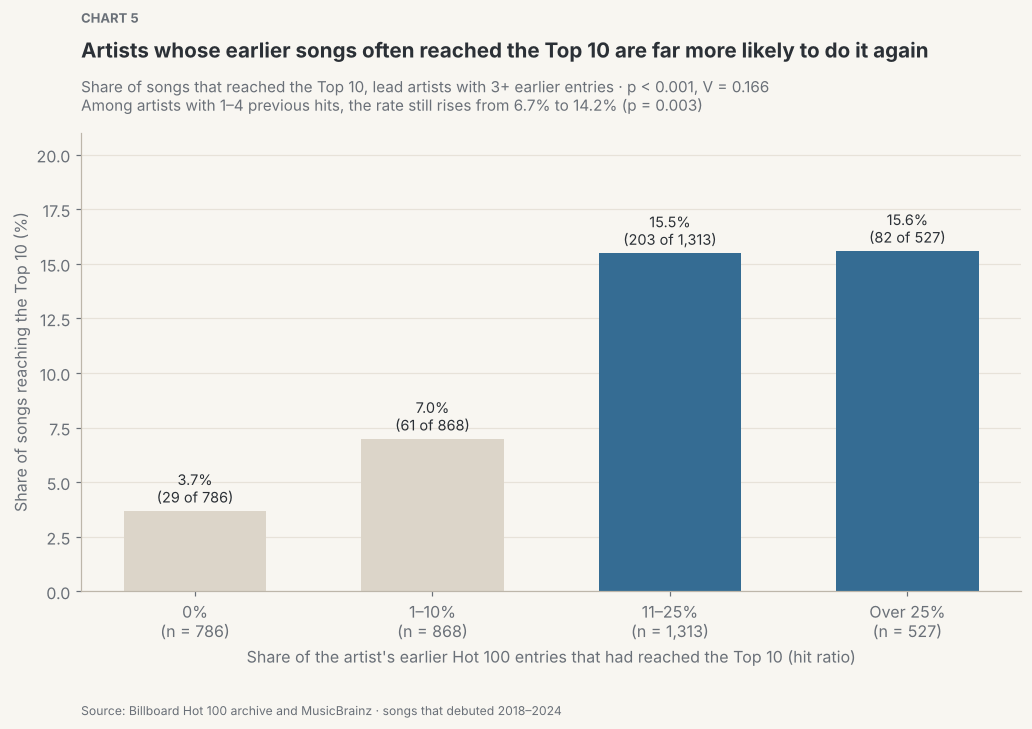

In [37]:
# Chart 5 — bars: Top 10 rate by hit ratio, artists with at least 3 earlier entries.
data = q2a["summary"]
fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.bar([f"{b}\n(n = {n:,})" for b, n in zip(data.index, data["songs"])], data["top10_rate_pct"],
              color=[CONTEXT, CONTEXT, FOCUS, FOCUS], width=0.6)
ax.bar_label(bars, labels=[f"{r:.1f}%\n({k} of {n:,})" for r, k, n in
                           zip(data["top10_rate_pct"], data["top10"], data["songs"])], padding=3, fontsize=9.5)
ax.set_xlabel("Share of the artist's earlier Hot 100 entries that had reached the Top 10 (hit ratio)")
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 21)
ax.grid(axis="y")
ax.set_axisbelow(True)
within = q2a_within.loc["1-4"]
chart_titles(ax, 5, "Artists whose earlier songs often reached the Top 10 are far more likely to do it again",
             f"Share of songs that reached the Top 10, lead artists with 3+ earlier entries · p < 0.001, V = {q2a['v']:.3f}\n"
             f"Among artists with 1–4 previous hits, the rate still rises from {within.iloc[1]:.1f}% to {within.iloc[3]:.1f}% "
             f"(p = {within['p_value']:.3f})")
show_chart(fig)

**Finding.** The Top 10 rate climbs from 3.7% for artists with no earlier hits to 7.0% at a 1-10% hit ratio
and about 15.5% above 10% (χ²(3) = 96.6, p < 0.001, V = 0.166). Among artists with 1-4 previous hits, the
ratio still separates them: 6.7% at 1-10% against 14.2% above 25% (p = 0.003).

**Interpretation.** How often an artist's songs become hits is at least as informative as how many hits they
have: its effect size (V = 0.166) is slightly larger than the hit count's in Q2 (V = 0.158). Within the 5-9 and
10+ hit groups the ratio does not add a significant difference (p = 0.08 and p = 0.19), so the extra information
is mostly about less-established artists. The two measures overlap heavily; whether both belong in a model is a
question for the modelling phase.

#### Q2b. Among artists without a previous Top 10, how does the rate vary with the number of earlier chart entries?

**Research question.** Among the 1,527 songs by artists with no previous Top 10, we compare the Top 10 rate
by how many Hot 100 entries the artist had before: none (first entry), 1-2, 3-5, 6-10, or 11 or more.

**Hypothesis.** H₀: the Top 10 rate is the same however many times the artist has charted before. H₁: it
differs.

In [38]:
# Q2b test: among artists with no previous Top 10, compare Top 10 rates by number of earlier chart entries.
never_hit = train[train["prior_hits"] == 0].copy()
never_hit["earlier_entries"] = pd.cut(never_hit["prior_entries"], [-1, 0, 2, 5, 10, np.inf],
                                      labels=["First entry", "1–2", "3–5", "6–10", "11+"])
q2b = chi_square(never_hit, "earlier_entries")
report(q2b, "Q2b: no previous Top 10, by number of earlier chart entries")

# Same comparison for songs that were the artist's only debut that week (multi-song weeks are more common for veterans).
print("Songs that were the artist's only debut that week:")
display(top10_rates(never_hit[never_hit["album_debut_bucket"] == "1"], "earlier_entries"))

Q2b: no previous Top 10, by number of earlier chart entries
-----------------------------------------------------------
  chi2(4) = 18.7   p = 0.000902   Cramer's V = 0.111 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
earlier_entries,,,
First entry,438,41,9.4
1–2,303,19,6.3
3–5,267,12,4.5
6–10,177,9,5.1
11+,342,8,2.3


Songs that were the artist's only debut that week:


,songs,top10,top10_rate_pct
earlier_entries,,,
First entry,380,38,10.0
1–2,259,19,7.3
3–5,202,10,5.0
6–10,134,6,4.5
11+,157,3,1.9


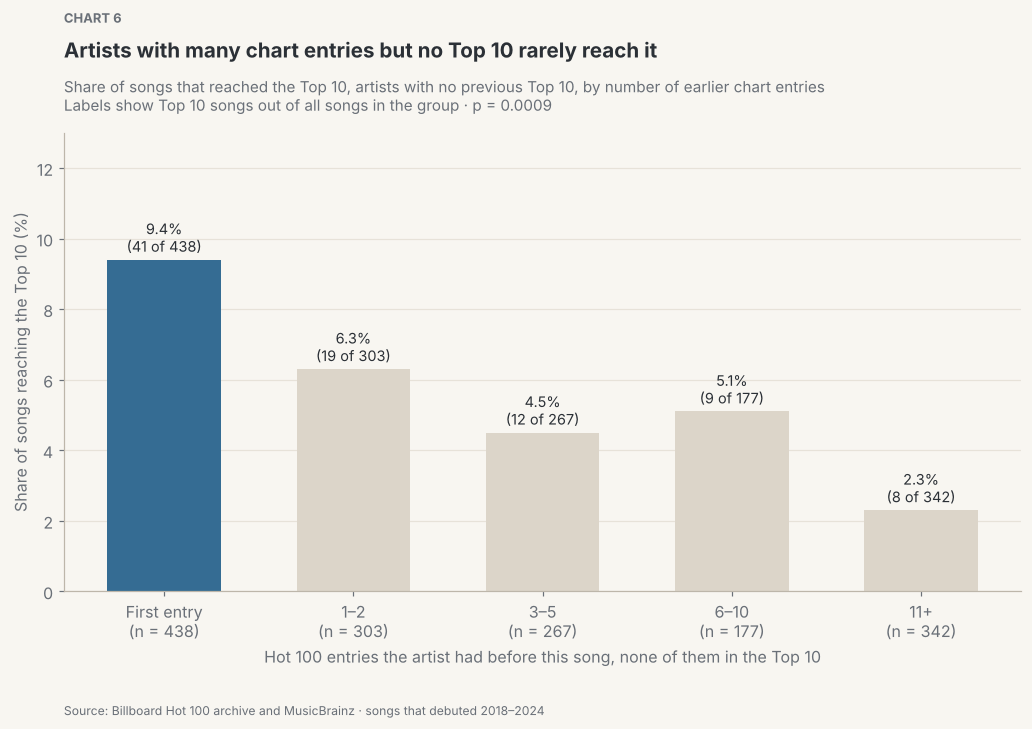

In [39]:
# Chart 6 — bars: artists with no previous Top 10, by number of earlier chart entries.
data = q2b["summary"]
fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.bar([f"{b}\n(n = {n:,})" for b, n in zip(data.index, data["songs"])], data["top10_rate_pct"],
              color=[FOCUS if i == 0 else CONTEXT for i in range(len(data))], width=0.6)
ax.bar_label(bars, labels=[f"{r:.1f}%\n({k} of {n:,})" for r, k, n in
                           zip(data["top10_rate_pct"], data["top10"], data["songs"])], padding=3, fontsize=9.5)
ax.set_xlabel("Hot 100 entries the artist had before this song, none of them in the Top 10")
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 13)
ax.grid(axis="y")
ax.set_axisbelow(True)
chart_titles(ax, 6, "Artists with many chart entries but no Top 10 rarely reach it",
             "Share of songs that reached the Top 10, artists with no previous Top 10, by number of earlier chart entries\n"
             f"Labels show Top 10 songs out of all songs in the group · p = {q2b['p']:.4f}")
show_chart(fig)

**Finding.** A first chart entry reaches the Top 10 9.4% of the time (41 of 438 songs), against 2.3% for
artists with 11 or more earlier entries (8 of 342), with the groups in between at 4.5-6.3% (χ²(4) = 18.7,
p < 0.001, V = 0.111).

**Interpretation.** The "no previous hit" group mixes very different artists: those on their first entry sit
near the overall average, while long-time chart regulars without a hit rarely reach the Top 10. The pattern
holds for songs debuting alone too (10.0% vs 1.9%), so it is not just multi-song weeks. The middle groups
rest on 9-19 hits each, so their exact order should not be read into.

**Theme takeaway:** previous Top 10s counted at debut are strongly associated with success (Q2). The share of an
artist's songs that became hits is at least as telling as the count, especially for artists with 1-4 hits (Q2a),
and among artists without a hit, first-time entrants do far better than long-time chart regulars (Q2b).

### 4.3 Artist reach

Q3 measures how concentrated Top 10 songs are among a few artists. Q3a compares artists from inside and
outside the US, and Q3b checks whether that gap is really about track record.

#### Q3. How concentrated are Top 10 songs among a small number of artists?

**Research question.** We rank lead artists by how many Top 10 songs they had in 2018-2024 and measure what
share of all Top 10 songs, and of all songs, the top 5, 10, 25 and 50 artists account for.

**Hypothesis.** This question is descriptive, so there is no significance test: grouping artists by their own
hits and then testing their hit rate would be circular. The expectation is that Top 10 songs are far more
concentrated than songs in general.

In [40]:
# Q3 analysis: how concentrated are Top 10 songs among lead artists? (Descriptive: no test is needed to
# measure a share, and grouping artists by their own hits would make a test circular.)
hits_by_artist = train[train["top10"]].groupby("primary_artist").size().sort_values(ascending=False)
songs_by_artist = train.groupby("primary_artist").size()
print(f"lead artists with at least one song: {songs_by_artist.size:,}; with at least one Top 10: {hits_by_artist.size}")

rows = []
for k in [5, 10, 25, 50]:
    top = hits_by_artist.head(k).index
    rows.append({"top_artists": k, "share_of_top10_songs_pct": round(hits_by_artist.head(k).sum() / hits_by_artist.sum() * 100, 1),
                 "share_of_all_songs_pct": round(songs_by_artist[top].sum() / songs_by_artist.sum() * 100, 1)})
concentration = pd.DataFrame(rows).set_index("top_artists")
display(concentration)

print("The ten lead artists with the most Top 10 songs:")
display(pd.DataFrame({"top10_songs": hits_by_artist.head(10), "all_songs": songs_by_artist[hits_by_artist.head(10).index]}))

lead artists with at least one song: 757; with at least one Top 10: 146


,share_of_top10_songs_pct,share_of_all_songs_pct
top_artists,,
5,26.3,10.6
10,37.0,19.4
25,57.8,32.7
50,75.3,43.7


The ten lead artists with the most Top 10 songs:


,top10_songs,all_songs
primary_artist,,
Drake,44,139
Taylor Swift,37,185
Kendrick Lamar,14,37
Ariana Grande,11,55
J. Cole,10,40
Morgan Wallen,10,61
Post Malone,10,73
Future,10,108
Bad Bunny,9,72


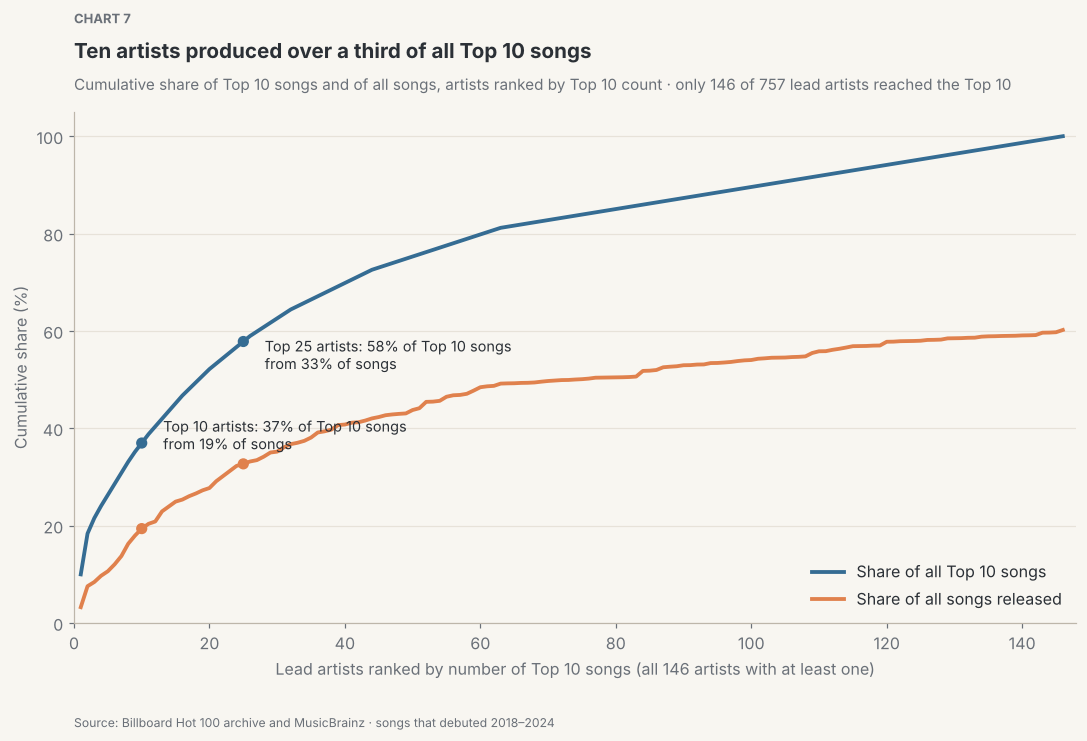

In [41]:
# Chart 7 — cumulative line: artists ranked by Top 10 songs; how quickly do they add up to all Top 10s?
ranked = hits_by_artist.reset_index(name="hits")
ranked["rank"] = np.arange(1, len(ranked) + 1)
ranked["cum_hits_pct"] = ranked["hits"].cumsum() / ranked["hits"].sum() * 100
ranked["cum_songs_pct"] = songs_by_artist[ranked["primary_artist"]].cumsum().values / songs_by_artist.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.plot(ranked["rank"], ranked["cum_hits_pct"], color=FOCUS, linewidth=2.5, label="Share of all Top 10 songs")
ax.plot(ranked["rank"], ranked["cum_songs_pct"], color=SECOND, linewidth=2.5, label="Share of all songs released")
for k in [10, 25]:
    row = ranked.iloc[k - 1]
    ax.scatter([k, k], [row["cum_hits_pct"], row["cum_songs_pct"]], color=[FOCUS, SECOND], s=40, zorder=3)
    ax.annotate(f"Top {k} artists: {row['cum_hits_pct']:.0f}% of Top 10 songs\nfrom {row['cum_songs_pct']:.0f}% of songs",
                (k, row["cum_hits_pct"]), textcoords="offset points", xytext=(14, -4 if k == 10 else -18), fontsize=9.5)
ax.set_xlabel(f"Lead artists ranked by number of Top 10 songs (all {len(ranked)} artists with at least one)")
ax.set_ylabel("Cumulative share (%)")
ax.set_xlim(0, len(ranked) + 2)
ax.set_ylim(0, 105)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="lower right")
chart_titles(ax, 7, "Ten artists produced over a third of all Top 10 songs",
             f"Cumulative share of Top 10 songs and of all songs, artists ranked by Top 10 count · "
             f"only {len(ranked)} of {songs_by_artist.size:,} lead artists reached the Top 10")
show_chart(fig)

**Finding.** Only 146 of 757 lead artists reached the Top 10 at all. The top 10 artists produced 37.0% of all Top
10 songs from 19.4% of the songs, and the top 25 produced 57.8% from 32.7%. Drake (44) and Taylor Swift (37) alone
account for 18% of Top 10 songs.

**Interpretation.** Top 10 success is concentrated in a small group of artists who also release a lot of music,
which is why artist track record (Q2) is such a strong signal and why a few names can move any comparison. It also
explains a caution used throughout: results for small groups can be driven by one or two artists, as Q3b shows.

#### Q3a. Do songs by artists from outside the US reach the Top 10 more often than songs by US artists?

**Research question.** We compare the Top 10 rate of songs whose lead artist is from the US with songs whose lead
artist is from elsewhere, using the artist's country in MusicBrainz (4,222 training songs with a known country),
and then break the outside-US group down by country (countries with at least 40 songs).

**Hypothesis.** H₀: the Top 10 rate is the same for US and outside-US artists. H₁: it differs.

In [42]:
# Q3a test: lead artist's country (from MusicBrainz) — US vs outside the US, then by country.
artists = pd.read_csv("data/raw/mb_artists.csv")
artists = artists[~artists.duplicated("artist_mbid")]
train["lead_mbid"] = train["artist_mbids"].map(lambda ids: ids.split("|")[0] if isinstance(ids, str) else np.nan)
train = train.merge(artists[["artist_mbid", "country"]], left_on="lead_mbid", right_on="artist_mbid", how="left")
train["origin"] = np.where(train["country"] == "US", "US", "Outside the US")
train.loc[train["country"].isna(), "origin"] = np.nan
print("training songs with no known artist country (left out):", train["origin"].isna().sum())

q3a = chi_square(train, "origin")
report(q3a, "Q3a: Top 10 rate, US vs outside the US")

big = train["country"].value_counts()
q3a_country = chi_square(train[train["country"].isin(big[big >= 40].index)], "country")
report(q3a_country, "Q3a: Top 10 rate by country (countries with 40+ songs)")

training songs with no known artist country (left out): 71
Q3a: Top 10 rate, US vs outside the US
--------------------------------------
  chi2(1) = 31.0   p = 2.63e-08   Cramer's V = 0.086 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
origin,,,
Outside the US,800,126,15.8
US,3422,309,9.0


Q3a: Top 10 rate by country (countries with 40+ songs)
------------------------------------------------------
  chi2(6) = 80.0   p = 3.58e-15   Cramer's V = 0.140 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
country,,,
CA,269,64,23.8
CO,44,2,4.5
GB,135,25,18.5
KR,73,12,16.4
MX,45,0,0.0
PR,121,9,7.4
US,3422,309,9.0


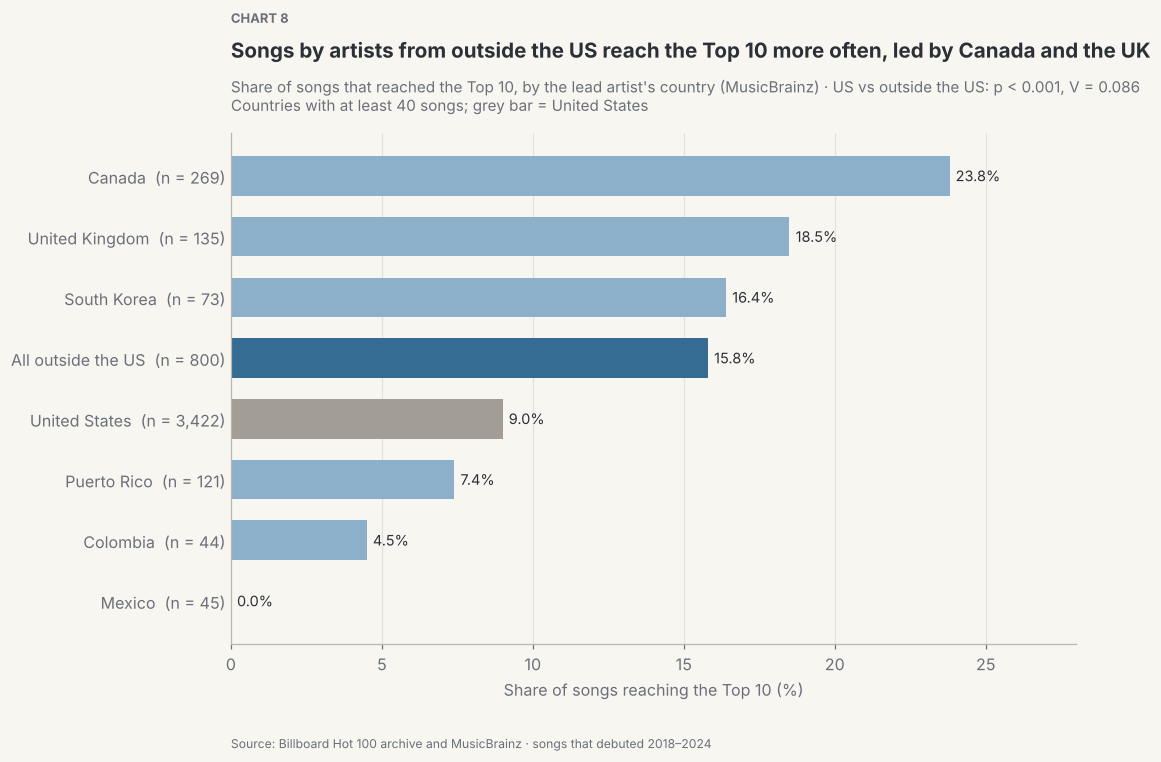

In [43]:
# Chart 8 — horizontal bars: Top 10 rate by lead artist's country (40+ songs), with the US and the
# outside-US total for reference.
data = q3a_country["summary"].drop(index="US")
data.loc["All outside the US"] = q3a["summary"].loc["Outside the US"]
data.loc["US"] = q3a["summary"].loc["US"]
data = data.sort_values("top10_rate_pct")
names = {"CA": "Canada", "GB": "United Kingdom", "KR": "South Korea", "PR": "Puerto Rico", "CO": "Colombia",
         "MX": "Mexico", "US": "United States", "All outside the US": "All outside the US"}
colours = [REF if c == "US" else (FOCUS if c == "All outside the US" else FOCUS_LIGHT) for c in data.index]

fig, ax = plt.subplots(figsize=(10, 5.8))
bars = ax.barh([f"{names.get(c, c)}  (n = {int(n):,})" for c, n in zip(data.index, data["songs"])], data["top10_rate_pct"],
               color=colours, height=0.65)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9.5)
ax.set_xlabel("Share of songs reaching the Top 10 (%)")
ax.set_xlim(0, 28)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
ax.set_axisbelow(True)
chart_titles(ax, 8, "Songs by artists from outside the US reach the Top 10 more often, led by Canada and the UK",
             f"Share of songs that reached the Top 10, by the lead artist's country (MusicBrainz) · "
             f"US vs outside the US: p < 0.001, V = {q3a['v']:.3f}\nCountries with at least 40 songs; grey bar = United States")
show_chart(fig)

**Finding.** Songs by artists from outside the US reach the Top 10 at 15.8% (800 songs), against 9.0% for US artists
(3,422 songs), with χ²(1) = 31.0 and p < 0.001 (V = 0.086). By country, Canada leads at 23.8% (269 songs) and the
United Kingdom follows at 18.5% (135), while Puerto Rico (7.4%), Colombia (4.5%) and Mexico (0 of 45) sit below the US.

**Interpretation.** Artists who break into the US chart from abroad tend to be already-successful international stars,
so "outside the US" is not one group: English-speaking and K-pop acts convert well, Latin-market acts much less. The
overall effect is small (V = 0.086) but the country differences are larger (V = 0.140). Q3b checks whether track
record explains the gap; 71 songs whose lead artist has no country in MusicBrainz are left out.

#### Q3b. Does the origin gap hold among artists with a similar number of previous hits?

**Research question.** Within each previous-hit group (none, 1-4, 5-9, 10 or more), we compare the Top 10 rate of US
and outside-US artists. We also repeat the overall comparison without the three outside-US artists with the most Top
10 songs, to see how much a few stars drive the gap.

**Hypothesis.** H₀: within each previous-hit group, US and outside-US artists have the same Top 10 rate. H₁: the gap
remains.

In [44]:
# Q3b test: does the origin gap hold among artists with a similar number of previous Top 10s?
train["prior_hit_group"] = pd.cut(train["prior_hits"], [-1, 0, 4, 9, np.inf], labels=["0", "1-4", "5-9", "10+"])
rows = []
for group, g in train.groupby("prior_hit_group", observed=True):
    r = chi_square(g, "origin")
    s = r["summary"]
    rows.append({"previous_hits": group, "n_us": s.loc["US", "songs"], "n_outside": s.loc["Outside the US", "songs"],
                 "rate_us": s.loc["US", "top10_rate_pct"], "rate_outside": s.loc["Outside the US", "top10_rate_pct"],
                 "p_value": round(r["p"], 4)})
q3b = pd.DataFrame(rows).set_index("previous_hits")
q3b["gap_pts"] = q3b["rate_outside"] - q3b["rate_us"]
display(q3b)

# How much do a few stars drive it? Repeat without the three outside-US artists with the most Top 10s.
outside = train[train["origin"] == "Outside the US"]
top3 = outside[outside["top10"]].groupby("primary_artist").size().sort_values(ascending=False).head(3)
print("Outside-US artists with the most Top 10 songs:", dict(top3))
print(f"share of outside-US Top 10 songs from these three: {top3.sum() / outside['top10'].sum():.1%}")
q3b_check = chi_square(train[~train["primary_artist"].isin(top3.index)], "origin")
report(q3b_check, "Q3b check: US vs outside the US, without those three artists")

,n_us,n_outside,rate_us,rate_outside,p_value,gap_pts
previous_hits,,,,,,
0,1192,292,5.6,6.8,0.5080,1.2
1-4,1191,212,7.9,14.6,0.0024,6.7
5-9,370,76,11.6,21.1,0.0429,9.5
10+,669,220,15.7,26.8,0.0003,11.1


Outside-US artists with the most Top 10 songs: {'Drake': np.int64(44), 'Bad Bunny': np.int64(9), 'The Weeknd': np.int64(8)}
share of outside-US Top 10 songs from these three: 48.4%
Q3b check: US vs outside the US, without those three artists
------------------------------------------------------------
  chi2(1) = 4.1   p = 0.0426   Cramer's V = 0.032 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
origin,,,
Outside the US,548,65,11.9
US,3422,309,9.0


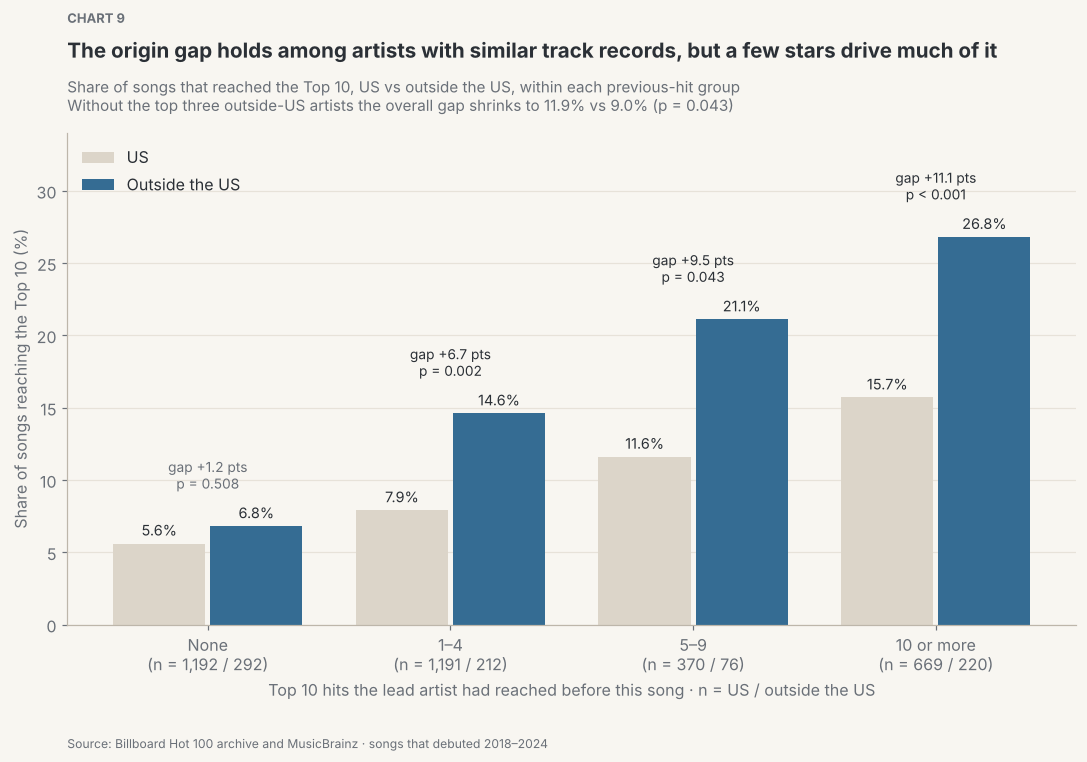

In [45]:
# Chart 9 — grouped bars: US vs outside the US within each previous-hit group.
x = np.arange(len(q3b))
fig, ax = plt.subplots(figsize=(10, 5.8))
bars_us = ax.bar(x - 0.2, q3b["rate_us"], width=0.38, color=CONTEXT, label="US")
bars_out = ax.bar(x + 0.2, q3b["rate_outside"], width=0.38, color=FOCUS, label="Outside the US")
for bars in (bars_us, bars_out):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9.5)
for i, (gap_value, p) in enumerate(zip(q3b["gap_pts"], q3b["p_value"])):
    ax.text(i, max(q3b["rate_us"].iloc[i], q3b["rate_outside"].iloc[i]) + 2.6,
            f"gap {gap_value:+.1f} pts\n" + ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"),
            ha="center", fontsize=9, color=TEXT if p < ALPHA else MUTED)
names = {"0": "None", "1-4": "1–4", "5-9": "5–9", "10+": "10 or more"}
ax.set_xticks(x, [f"{names[g]}\n(n = {a:,} / {b:,})" for g, a, b in zip(q3b.index, q3b["n_us"], q3b["n_outside"])])
ax.set_xlabel("Top 10 hits the lead artist had reached before this song · n = US / outside the US")
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 34)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="upper left")
chart_titles(ax, 9, "The origin gap holds among artists with similar track records, but a few stars drive much of it",
             f"Share of songs that reached the Top 10, US vs outside the US, within each previous-hit group\n"
             f"Without the top three outside-US artists the overall gap shrinks to "
             f"{q3b_check['summary'].loc['Outside the US', 'top10_rate_pct']:.1f}% vs {q3b_check['summary'].loc['US', 'top10_rate_pct']:.1f}% "
             f"(p = {q3b_check['p']:.3f})")
show_chart(fig)

**Finding.** The gap holds in every group of artists with at least one previous hit: 14.6% vs 7.9% at 1-4 hits
(p = 0.002), 21.1% vs 11.6% at 5-9 (p = 0.043) and 26.8% vs 15.7% at 10 or more (p < 0.001). It does not appear among
artists with no previous hit (6.8% vs 5.6%, p = 0.51).

**Interpretation.** Track record alone does not explain the origin gap, but a few stars carry much of it: Drake, Bad
Bunny and The Weeknd produced 48% of outside-US Top 10 songs, and without them the overall gap shrinks to 11.9% vs 9.0%
(p = 0.043, a negligible effect). The safest reading is that established international stars convert unusually well on
the US chart, not that being from outside the US helps in general.

**Theme takeaway:** Top 10 songs are concentrated in a small set of artists (Q3). Outside-US artists convert better
than US artists (Q3a), and the gap survives controlling for previous hits, but it is carried largely by a handful of
international stars (Q3b).

### 4.4 Release strategy

Q4 looks at how many songs an artist debuts in the same week. Q4a checks whether the single format matters once that
is accounted for, and Q4b checks that the pattern holds in both of the largest genres.

#### Q4. Is the number of songs an artist debuts in the same week associated with Top 10 success?

**Research question.** We compare the Top 10 rate by how many songs the same lead artist debuted on the Hot
100 that week (1, 2-4, 5-9, 10 or more), overall and separately for artists with and without a previous Top
10. The variable counts chart debuts only, songs that actually entered the Hot 100, not every track on an
album; the first lines of the cell below recount it to confirm.

**Hypothesis.** H₀: the number of same-week debuts is unrelated to the Top 10 rate. H₁: it is associated
with it.

In [46]:
# Q4 check: the variable counts CHART DEBUTS, i.e. songs by the same lead artist that entered the Hot 100
# in the same week, not every track on an album. Recount it from the data to confirm.
recount = df.groupby(["primary_artist", "first_chart_date"])["title"].transform("count")
print(f"recount matches same_artist_debuts_that_week for {(recount == df['same_artist_debuts_that_week']).mean():.1%} of songs")

# Q4 test: Top 10 rate by how many songs the artist debuted that week, overall and by artist history.
q4 = chi_square(train, "album_debut_bucket")
report(q4, "Q4: Top 10 rate by same-week debuts by the same artist")
for group in STATUS_ORDER:
    report(chi_square(train[train["artist_status"] == group], "album_debut_bucket"), f"Q4: {group}")

recount matches same_artist_debuts_that_week for 100.0% of songs
Q4: Top 10 rate by same-week debuts by the same artist
------------------------------------------------------
  chi2(3) = 44.5   p = 1.16e-09   Cramer's V = 0.102 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,2123,246,11.6
10+,1379,163,11.8
2-4,366,23,6.3
5-9,425,9,2.1


Q4: No previous Top 10
----------------------
  chi2(3) = 7.1   p = 0.0676   Cramer's V = 0.068 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,1132,76,6.7
10+,144,6,4.2
2-4,129,5,3.9
5-9,122,2,1.6


Q4: Previous Top 10
-------------------
  chi2(3) = 52.7   p = 2.11e-11   Cramer's V = 0.138 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,991,170,17.2
10+,1235,157,12.7
2-4,237,18,7.6
5-9,303,7,2.3


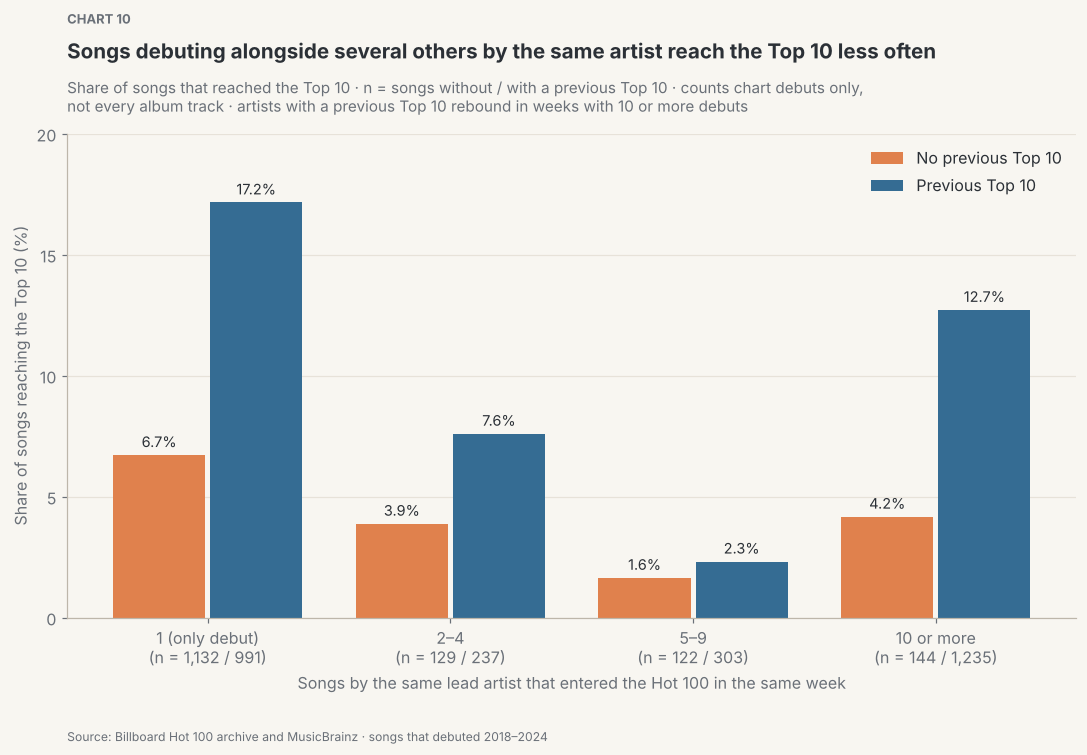

In [47]:
# Chart 10 — grouped bars: Top 10 rate by same-week debuts by the same artist, split by artist history.
order = ["1", "2-4", "5-9", "10+"]
names = {"1": "1 (only debut)", "2-4": "2–4", "5-9": "5–9", "10+": "10 or more"}
rates = train.pivot_table(index="album_debut_bucket", columns="artist_status", values="top10", aggfunc="mean").reindex(order) * 100
sizes = train.pivot_table(index="album_debut_bucket", columns="artist_status", values="top10", aggfunc="size").reindex(order)
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(10, 5.8))
for offset, group, colour in [(-0.2, "No previous Top 10", SECOND), (0.2, "Previous Top 10", FOCUS)]:
    bars = ax.bar(x + offset, rates[group], width=0.38, color=colour, label=group)
    ax.bar_label(bars, labels=[f"{r:.1f}%" for r in rates[group]], padding=3, fontsize=9.5)
ax.set_xticks(x, [f"{names[b]}\n(n = {a:,} / {c:,})" for b, a, c in
                  zip(order, sizes["No previous Top 10"], sizes["Previous Top 10"])])
ax.set_xlabel("Songs by the same lead artist that entered the Hot 100 in the same week")
ax.set_ylabel("Share of songs reaching the Top 10 (%)")
ax.set_ylim(0, 20)
ax.set_yticks(range(0, 21, 5))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="upper right")
chart_titles(ax, 10, "Songs debuting alongside several others by the same artist reach the Top 10 less often",
             "Share of songs that reached the Top 10 · n = songs without / with a previous Top 10 · counts chart debuts only,\n"
             "not every album track · artists with a previous Top 10 rebound in weeks with 10 or more debuts")
show_chart(fig)

**Finding.** Songs that were the artist's only debut that week reach the Top 10 at 11.6%, against 6.3% with
2-4 same-week debuts and 2.1% with 5-9 (χ²(3) = 44.5, p < 0.001, V = 0.102). For artists with a previous Top
10 the pattern is clear (17.2%, 7.6%, 2.3%, then 12.7% at 10 or more, p < 0.001); for artists without one it
points the same way (6.7% down to 1.6%) but is not significant (p = 0.068).

**Interpretation.** More same-week debuts go with lower Top 10 rates up to 5-9 songs. The rebound at 10 or
more comes from established artists, whose very large releases still reach the Top 10 less often than their
solo debuts (12.7% vs 17.2%). This is an association: artists choose how many songs to release, and bigger
releases may differ in other ways. Because the variable counts only songs that charted, it measures how many
tracks broke onto the chart, not album size.

#### Q4a. Do singles and album tracks differ, and does any gap remain among songs debuting alone?

**Research question.** We compare the Top 10 rate of songs first released as singles, album tracks and EP
tracks (as listed by MusicBrainz), for all songs and then only for songs debuting alone. Most album tracks
debut alongside other songs, so Q4's pattern could explain an apparent singles advantage.

**Hypothesis.** H₀: among songs debuting alone, the rate is the same for singles, album tracks and EP tracks.
H₁: singles still differ.

In [48]:
# Q4a test: singles vs album tracks vs EP tracks, for all songs and then for songs debuting alone.
types = ["Single", "Album", "EP"]
typed = train[train["release_type"].isin(types)]
typed_alone = typed[typed["album_debut_bucket"] == "1"]

q4a_all = chi_square(typed, "release_type")
report(q4a_all, "Q4a: Top 10 rate by release type — ALL songs")
q4a_alone = chi_square(typed_alone, "release_type")
report(q4a_alone, "Q4a: the same test — songs debuting ALONE")
for name, data in [("all songs", typed), ("debuting alone", typed_alone)]:
    r = top10_rates(data, "release_type")["top10_rate_pct"]
    print(f"single minus album track, {name}: {r['Single'] - r['Album']:+.1f} percentage points")

Q4a: Top 10 rate by release type — ALL songs
--------------------------------------------
  chi2(2) = 9.5   p = 0.00845   Cramer's V = 0.048 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
release_type,,,
Album,2528,232,9.2
EP,117,8,6.8
Single,1539,184,12.0


Q4a: the same test — songs debuting ALONE
-----------------------------------------
  chi2(2) = 3.1   p = 0.215   Cramer's V = 0.039 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
release_type,,,
Album,612,70,11.4
EP,75,4,5.3
Single,1387,166,12.0


single minus album track, all songs: +2.8 percentage points
single minus album track, debuting alone: +0.6 percentage points


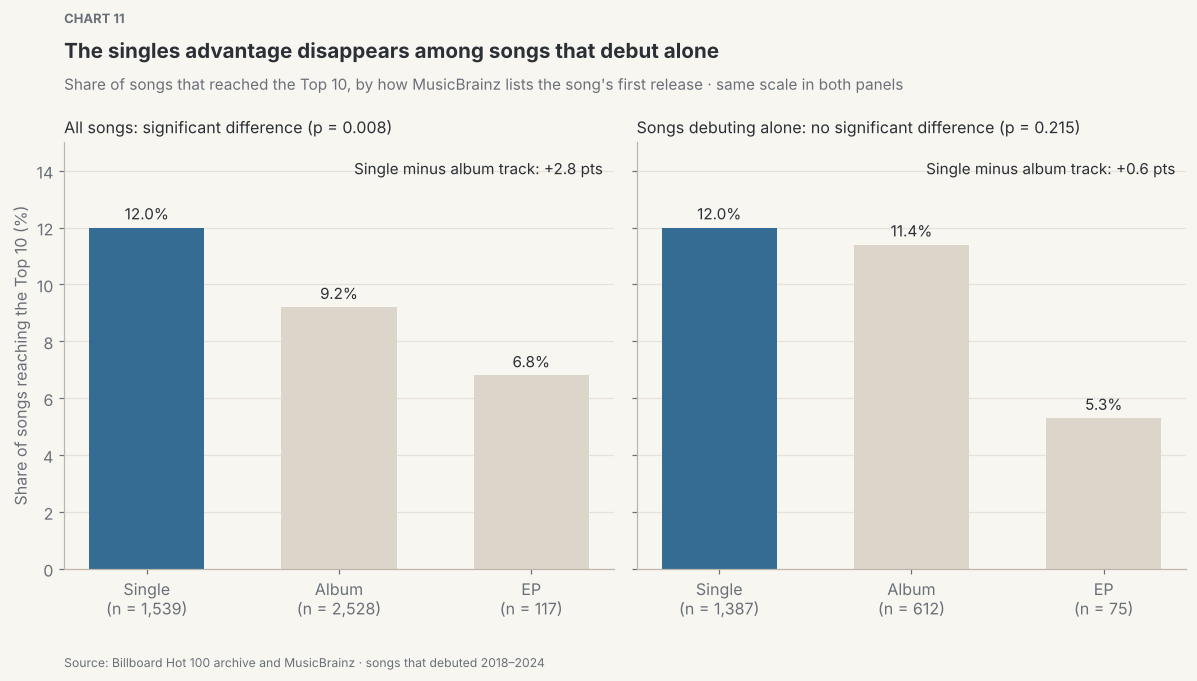

In [49]:
# Chart 11 — two bar panels with the same y-axis; each panel states the single minus album-track gap.
panels = [("All songs", typed, q4a_all), ("Songs debuting alone", typed_alone, q4a_alone)]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
for ax, (name, data, result) in zip(axes, panels):
    rates = top10_rates(data, "release_type").loc[types]
    bars = ax.bar([f"{t}\n(n = {n:,})" for t, n in zip(types, rates["songs"])], rates["top10_rate_pct"],
                  color=[FOCUS if t == "Single" else CONTEXT for t in types], width=0.6)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)
    gap_value = rates.loc["Single", "top10_rate_pct"] - rates.loc["Album", "top10_rate_pct"]
    ax.text(0.98, 0.96, f"Single minus album track: {gap_value:+.1f} pts", transform=ax.transAxes,
            ha="right", va="top", fontsize=10, color=TEXT)
    verdict = "significant difference" if result["p"] < ALPHA else "no significant difference"
    ax.set_title(f"{name}: {verdict} (p = {result['p']:.3f})", fontsize=10.5, loc="left", color=TEXT)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[0].set_ylabel("Share of songs reaching the Top 10 (%)")
axes[0].set_ylim(0, 15)
chart_titles(axes[0], 11, "The singles advantage disappears among songs that debut alone",
             "Share of songs that reached the Top 10, by how MusicBrainz lists the song's first release · same scale in both panels",
             extra_space=20)
show_chart(fig)

**Finding.** Across all songs, singles reach the Top 10 2.8 points more often than album tracks (12.0% vs
9.2%, p = 0.008). Among songs debuting alone the gap shrinks to 0.6 points (12.0% vs 11.4%) and is not
significant (p = 0.215).

**Interpretation.** 90% of singles debut alone, against 24% of album tracks, so the overall singles advantage
largely reflects same-week debuts (Q4) rather than the single format itself. EP tracks are few (75 debuting
alone), and 109 songs with other release types are left out.

#### Q4b. Is the same-week debut pattern found in both hip-hop and pop?

**Research question.** We repeat Q4 separately for the two largest genres, hip-hop/rap (2,017 songs) and pop (796).
Hip-hop artists release far more multi-song weeks, so Q4's pattern could be a hip-hop habit rather than a general one.

**Hypothesis.** H₀: within each genre, the Top 10 rate is the same however many songs the artist debuts that week.
H₁: it differs.

In [50]:
# Q4b test: is the same-week debut pattern from Q4 found in both of the two largest genres?
q4b = {}
for genre in ["hip-hop/rap", "pop"]:
    q4b[genre] = chi_square(train[train["primary_genre"] == genre], "album_debut_bucket")
    report(q4b[genre], f"Q4b: same-week debuts by the same artist — {genre}")

Q4b: same-week debuts by the same artist — hip-hop/rap
------------------------------------------------------
  chi2(3) = 32.5   p = 4.18e-07   Cramer's V = 0.127 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,679,74,10.9
10+,842,90,10.7
2-4,232,12,5.2
5-9,264,2,0.8


Q4b: same-week debuts by the same artist — pop
----------------------------------------------
  chi2(3) = 8.5   p = 0.0362   Cramer's V = 0.104 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,497,103,20.7
10+,194,37,19.1
2-4,54,4,7.4
5-9,51,5,9.8


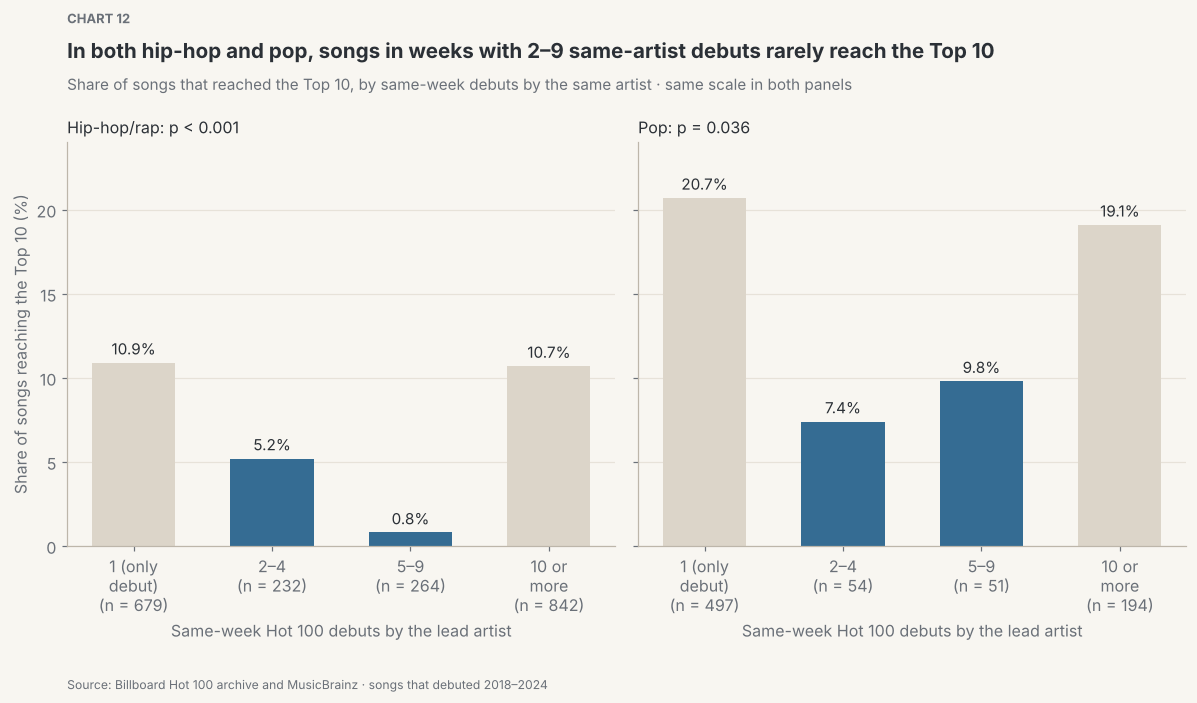

In [51]:
# Chart 12 — two panels with the same scale: Top 10 rate by same-week debuts, hip-hop and pop.
order = ["1", "2-4", "5-9", "10+"]
names = {"1": "1 (only\ndebut)", "2-4": "2–4", "5-9": "5–9", "10+": "10 or\nmore"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
for ax, genre in zip(axes, ["hip-hop/rap", "pop"]):
    s = q4b[genre]["summary"].reindex(order)
    bars = ax.bar([f"{names[b]}\n(n = {n:,})" for b, n in zip(order, s["songs"])], s["top10_rate_pct"],
                  color=[CONTEXT, FOCUS, FOCUS, CONTEXT], width=0.6)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)
    p = q4b[genre]["p"]
    ax.set_title(f"{GENRE_NAMES[genre]}: " + ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"),
                 fontsize=10.5, loc="left", color=TEXT)
    ax.set_xlabel("Same-week Hot 100 debuts by the lead artist")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[0].set_ylabel("Share of songs reaching the Top 10 (%)")
axes[0].set_ylim(0, 24)
chart_titles(axes[0], 12, "In both hip-hop and pop, songs in weeks with 2–9 same-artist debuts rarely reach the Top 10",
             "Share of songs that reached the Top 10, by same-week debuts by the same artist · same scale in both panels",
             extra_space=20)
show_chart(fig)

**Finding.** The pattern appears in both genres. In hip-hop, the rate falls from 10.9% for songs debuting alone to 5.2%
with 2-4 same-week debuts and 0.8% with 5-9 (p < 0.001, V = 0.127). In pop it falls from 20.7% to 7.4% and 9.8%
(p = 0.036, V = 0.104).

**Interpretation.** Weeks with 2-9 same-artist debuts go with much lower Top 10 rates in both genres, so Q4 is not just
a hip-hop effect. In both genres the rate recovers for 10 or more debuts (10.7% and 19.1%), the superstar album weeks
seen in Q4. Pop's middle groups are small (54 and 51 songs), so their exact rates are uncertain.

**Theme takeaway:** debuting alongside several of the artist's other songs goes with lower Top 10 rates (Q4), in both
hip-hop and pop (Q4b). The singles advantage largely disappears among songs debuting alone (Q4a).

### 4.5 Timing and lyrics

Q5 tests the chart debut month, and Q5a asks how the genre make-up of Top 10 songs changed over time. Q5b tests the
lyrics, the factor the project started out expecting to matter.

#### Q5. Does the Top 10 rate differ by chart debut month, and does any difference survive excluding big same-artist debut weeks?

**Research question.** We compare the Top 10 rate across the twelve months of the song's chart debut (the week it
first entered the Hot 100, not its release date). We then repeat the test without songs that debuted in a week
when their artist placed five or more songs on the chart at once, because superstar releases cluster in a few
months.

**Hypothesis.** H₀: the debut month is unrelated to the Top 10 rate. H₁: some months have higher rates.

In [52]:
# Q5 test: Top 10 rate by CHART DEBUT month (from first_chart_date, not the release date).
# Second test: drop songs that debuted in a week when their artist placed 5+ songs on the chart at once.
q5_all = chi_square(train, "debut_month")
report(q5_all, "Q5: Top 10 rate by chart debut month — ALL songs")

no_bomb = train[train["album_debut_bucket"].isin(["1", "2-4"])]
print(f"songs left after excluding 5+ same-artist debut weeks: {len(no_bomb):,} of {len(train):,}")
q5_nb = chi_square(no_bomb, "debut_month")
report(q5_nb, "Q5: the same test, EXCLUDING songs from 5+ same-artist debut weeks")

Q5: Top 10 rate by chart debut month — ALL songs
------------------------------------------------
  chi2(11) = 25.0   p = 0.00915   Cramer's V = 0.076 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_month,,,
1,288,26,9.0
2,300,26,8.7
3,355,25,7.0
4,361,39,10.8
5,392,59,15.1
6,370,36,9.7
7,414,36,8.7
8,360,34,9.4
9,352,34,9.7


songs left after excluding 5+ same-artist debut weeks: 2,489 of 4,293
Q5: the same test, EXCLUDING songs from 5+ same-artist debut weeks
------------------------------------------------------------------
  chi2(11) = 5.5   p = 0.906   Cramer's V = 0.047 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_month,,,
1,213,22,10.3
2,224,22,9.8
3,213,19,8.9
4,221,25,11.3
5,189,27,14.3
6,235,28,11.9
7,215,20,9.3
8,226,26,11.5
9,185,17,9.2


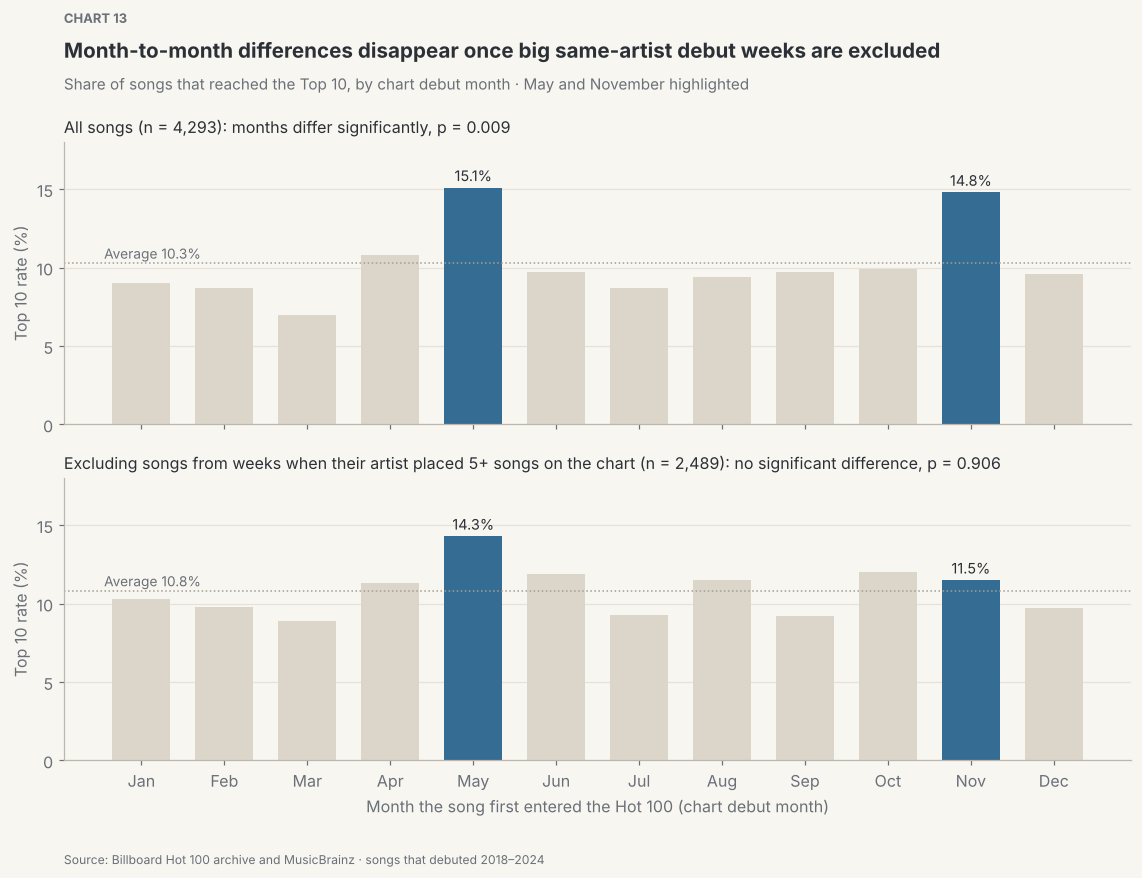

In [53]:
# Chart 13 — Top 10 rate by chart debut month, all songs vs excluding 5+ same-artist debut weeks (same scale).
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
panels = [("All songs", q5_all, train),
          ("Excluding songs from weeks when their artist placed 5+ songs on the chart", q5_nb, no_bomb)]

fig, axes = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True, sharey=True)
for ax, (name, result, data) in zip(axes, panels):
    rate = result["summary"]["top10_rate_pct"].reindex(range(1, 13))
    avg = data["top10"].mean() * 100
    bars = ax.bar(labels, rate, color=[FOCUS if m in (5, 11) else CONTEXT for m in rate.index], width=0.7)
    ax.bar_label(bars, labels=[f"{v:.1f}%" if m in (5, 11) else "" for m, v in rate.items()], fontsize=9.5, padding=2)
    ax.axhline(avg, color=REF, linewidth=1, linestyle=":")
    ax.text(-0.45, avg + 0.3, f"Average {avg:.1f}%", ha="left", fontsize=9, color=MUTED)
    verdict = "months differ significantly" if result["p"] < ALPHA else "no significant difference"
    ax.set_title(f"{name} (n = {len(data):,}): {verdict}, p = {result['p']:.3f}", fontsize=10.5, loc="left", color=TEXT)
    ax.set_ylabel("Top 10 rate (%)")
    ax.set_ylim(0, 18)
    ax.set_yticks(range(0, 16, 5))
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[1].set_xlabel("Month the song first entered the Hot 100 (chart debut month)")
chart_titles(axes[0], 13, "Month-to-month differences disappear once big same-artist debut weeks are excluded",
             "Share of songs that reached the Top 10, by chart debut month · May and November highlighted",
             extra_space=20)
show_chart(fig)

**Finding.** Across all songs, the Top 10 rate varies by chart debut month (p = 0.009), peaking in May (15.1%) and
November (14.8%) against 10.3% overall. After excluding the 1,804 songs from weeks when their artist placed five or
more songs on the chart, the differences are not significant (p = 0.906).

**Interpretation.** The apparent release season mostly reflects a few very large same-artist debut weeks. May stays
high after filtering (14.3%), but with 189 songs and a non-significant overall test it is consistent with chance.
The filter also removes 42% of songs, so part of the change in p-value is lost statistical power.

#### Q5a. How did the genre make-up of Top 10 songs change, and did any genre's own Top 10 rate change?

**Research question.** Two related comparisons across 2018-20, 2021-22 and 2023-24: (1) the share of each genre among
Top 10 songs (panel A), and (2) the Top 10 rate within each main genre (panel B). A genre's share of hits can rise
because more of its songs chart or because its songs convert better, so we test both.

**Hypothesis.** H₀: the genre make-up of Top 10 songs is the same in all three periods, and each genre's Top 10 rate
is constant. H₁: they changed.

In [54]:
# Q5a test: (1) has the genre MIX of Top 10 songs changed across three periods? (2) has each genre's
# Top 10 RATE changed? These are different questions, so they get different tests.
periods = pd.cut(train["debut_year"], [2017, 2020, 2022, 2024], labels=["2018–20", "2021–22", "2023–24"])
main = ["hip-hop/rap", "pop", "country", "R&B"]
train["period"] = periods
train["genre_group"] = np.where(train["primary_genre"].isin(main), train["primary_genre"], "other genres")
hits = train[train["top10"]]

mix = pd.crosstab(hits["period"], hits["genre_group"])
mix_chi2, mix_p, mix_dof, _ = stats.chi2_contingency(mix)
print(f"(1) genre mix of Top 10 songs by period: chi2({mix_dof}) = {mix_chi2:.1f}   p = {mix_p:.3g}   "
      f"-> {'REJECT the null' if mix_p < ALPHA else 'cannot reject the null'} at alpha = {ALPHA}")
share = pd.crosstab(hits["period"], hits["genre_group"], normalize="index").mul(100).round(1)[main + ["other genres"]]
display(share.assign(top10_songs=mix.sum(axis=1)))

print("(2) Top 10 rate by period within each main genre:")
rows = []
for genre in main:
    g = train[train["primary_genre"] == genre]
    r = chi_square(g, "period")
    rates = r["summary"]["top10_rate_pct"]
    rows.append({"genre": genre, **{f"rate_{k}": v for k, v in rates.items()},
                 **{f"n_{k}": v for k, v in r["summary"]["songs"].items()}, "p_value": round(r["p"], 3)})
rate_by_period = pd.DataFrame(rows).set_index("genre")
display(rate_by_period)

print("Each main genre's share of ALL debuts (not just Top 10 songs), by period (%):")
display(pd.crosstab(train["period"], train["genre_group"], normalize="index").mul(100).round(1)[main])

(1) genre mix of Top 10 songs by period: chi2(8) = 18.7   p = 0.0167   -> REJECT the null at alpha = 0.05


genre_group,hip-hop/rap,pop,country,R&B,other genres,top10_songs
period,,,,,,
2018–20,44.4,37.8,2.2,3.9,11.7,180
2021–22,39.3,29.3,6.4,10.0,15.0,140
2023–24,35.5,33.1,11.6,7.4,12.4,121


(2) Top 10 rate by period within each main genre:


,rate_2018–20,rate_2021–22,rate_2023–24,n_2018–20,n_2021–22,n_2023–24,p_value
genre,,,,,,,
hip-hop/rap,8.7,9.3,8.5,920,589,508,0.863
pop,19.7,18.6,17.3,345,220,231,0.770
country,2.4,6.2,7.0,166,144,200,0.124
R&B,5.8,9.8,15.8,121,143,57,0.098


Each main genre's share of ALL debuts (not just Top 10 songs), by period (%):


genre_group,hip-hop/rap,pop,country,R&B
period,,,,
2018–20,51.5,19.3,9.3,6.8
2021–22,46.2,17.2,11.3,11.2
2023–24,41.3,18.8,16.3,4.6


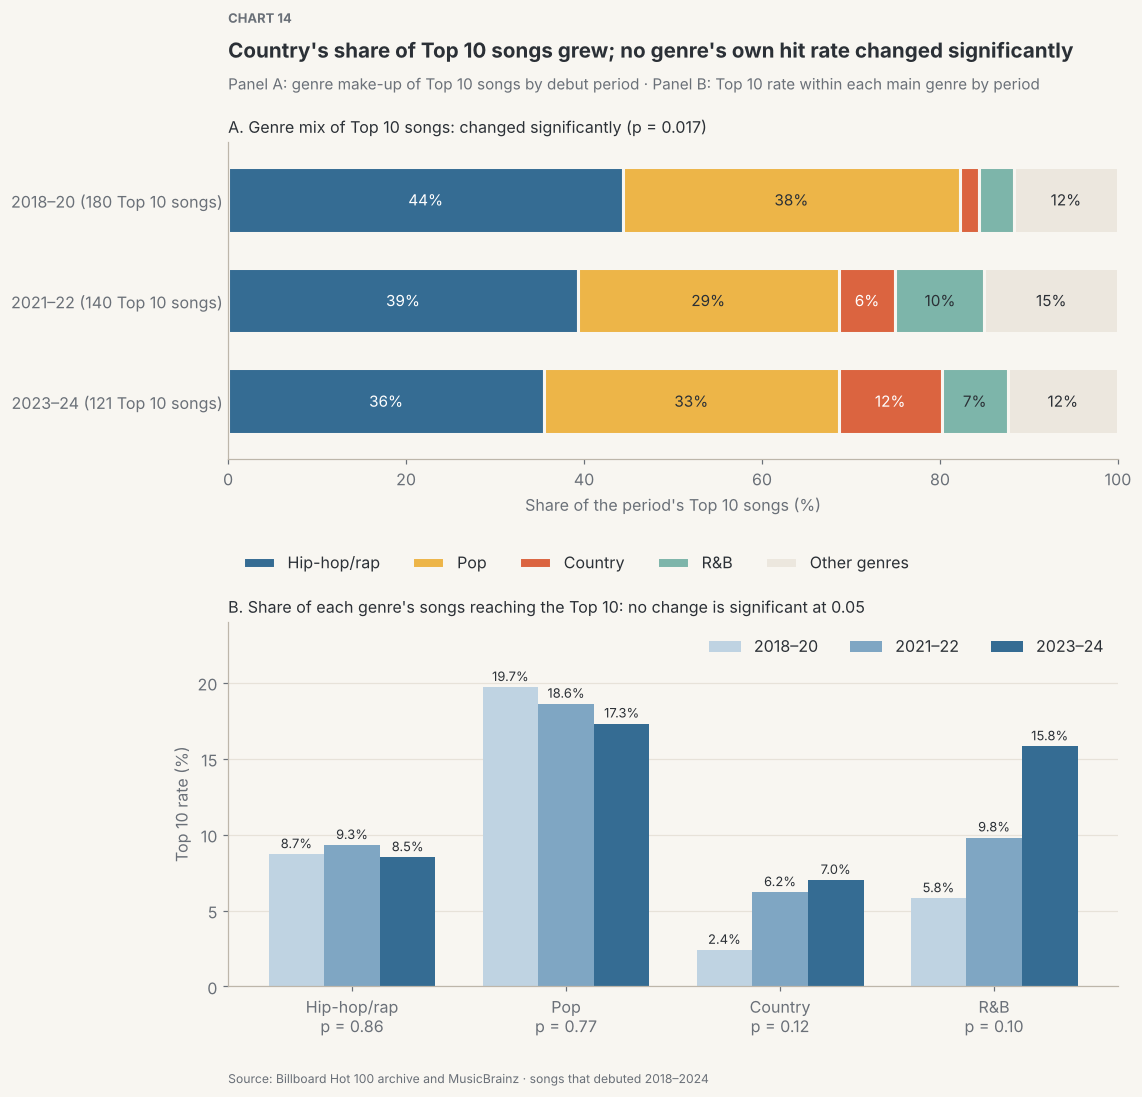

In [55]:
# Chart 14 — panel A: genre mix of Top 10 songs (100% stacked); panel B: each genre's Top 10 rate by period.
colours = {"hip-hop/rap": FOCUS, "pop": GOLD, "country": CORAL, "R&B": SEAFOAM, "other genres": PALE}
period_names = ["2018–20", "2021–22", "2023–24"]
period_colours = ["#BFD3E2", "#7FA6C3", FOCUS]                  # light to dark = earlier to later

fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(10.5, 9), gridspec_kw={"height_ratios": [1, 1.15]})
plot_share = share.iloc[::-1].rename(columns=lambda c: GENRE_NAMES.get(c, "Other genres"))
plot_share.plot(kind="barh", stacked=True, color=[colours[c] for c in share.columns], width=0.65,
                edgecolor=BACKGROUND, linewidth=2, ax=ax_a)
for bars, genre in zip(ax_a.containers, share.columns):
    ax_a.bar_label(bars, labels=[f"{v:.0f}%" if v >= 6 else "" for v in share[genre].iloc[::-1]],
                   label_type="center", fontsize=10, color="white" if genre in ("hip-hop/rap", "country") else TEXT)
ax_a.set_yticks(range(3), [f"{p} ({n} Top 10 songs)" for p, n in zip(period_names[::-1], mix.sum(axis=1).iloc[::-1])])
ax_a.set_xlabel("Share of the period's Top 10 songs (%)")
ax_a.set_ylabel("")
ax_a.set_xlim(0, 100)
ax_a.tick_params(axis="y", length=0)
ax_a.legend(title="", ncol=5, loc="upper left", bbox_to_anchor=(0, -0.25))
ax_a.set_title(f"A. Genre mix of Top 10 songs: changed significantly (p = {mix_p:.3f})", fontsize=10.5, loc="left", color=TEXT)

x = np.arange(len(main))
for k, (period, colour) in enumerate(zip(period_names, period_colours)):
    bars = ax_b.bar(x + (k - 1) * 0.26, rate_by_period[f"rate_{period}"], width=0.26, color=colour, label=period)
    ax_b.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8.5)
ax_b.set_xticks(x, [f"{GENRE_NAMES[g]}\np = {rate_by_period.loc[g, 'p_value']:.2f}" for g in main])
ax_b.set_ylabel("Top 10 rate (%)")
ax_b.set_ylim(0, 24)
ax_b.grid(axis="y")
ax_b.set_axisbelow(True)
ax_b.legend(title="", ncol=3, loc="upper right")
ax_b.set_title("B. Share of each genre's songs reaching the Top 10: no change is significant at 0.05",
               fontsize=10.5, loc="left", color=TEXT)
chart_titles(ax_a, 14, "Country's share of Top 10 songs grew; no genre's own hit rate changed significantly",
             "Panel A: genre make-up of Top 10 songs by debut period · Panel B: Top 10 rate within each main genre by period",
             extra_space=20)
show_chart(fig)

**Finding.** The genre make-up of Top 10 songs changed (p = 0.017): country's share rose from 2.2% to 11.6% and hip-hop's
fell from 44.4% to 35.5%, while pop stayed near a third. No main genre's own Top 10 rate changed significantly (country
2.4% to 7.0%, p = 0.12; R&B 5.8% to 15.8%, p = 0.10).

**Interpretation.** Country's growing share of hits comes at least partly from more country songs charting (9.3% to
16.3% of all debuts); its higher hit rate points the same way but is not significant. For modelling, the genre mix of
the 2025-26 test songs may differ from training. Each period has only 121-180 Top 10 songs.

#### Q5b. Do Top 10 songs differ from other songs on four lyric measures?

**Research question.** We compare Top 10 songs with songs that peaked at 11-100 on word count, unique-word
ratio, repetition score and words per line (4,274 training songs with lyrics).

Unique-word ratio, explained: the lyric "baby baby baby oh" has 4 words but only 2 different ones, so its ratio
is 2 ÷ 4 = 0.5. Repetition score is the share of lines that appear more than once.

**Hypothesis.** H₀: each measure is distributed the same way in both groups. H₁: they differ; the "catchiness"
idea predicts hits are more repetitive with a smaller vocabulary.

In [56]:
# Q5b test: compare four lyric measures between Top 10 songs and the rest (songs with lyrics).
lyric_cols = ["word_count", "unique_word_ratio", "repetition_score", "avg_line_length"]
rows = []
for col in lyric_cols:
    r = mann_whitney(train, col)
    rows.append({"feature": col, "median_top10": round(r["median_top10"], 3), "median_other": round(r["median_other"], 3),
                 "difference": round(r["median_top10"] - r["median_other"], 3),
                 "effect_r": round(r["effect_r"], 3), "p_value": float(f"{r['p']:.3g}"),
                 "significant": "yes" if r["p"] < ALPHA else "no"})
q5b = pd.DataFrame(rows).set_index("feature")
print(f"Mann-Whitney U, n = {r['n_top10']} Top 10 vs {r['n_other']:,} others (songs with lyrics only)")
print("effect_r: rank-biserial correlation; under 0.1 in size is negligible\n")
display(q5b)

Mann-Whitney U, n = 439 Top 10 vs 3,835 others (songs with lyrics only)
effect_r: rank-biserial correlation; under 0.1 in size is negligible



,median_top10,median_other,difference,effect_r,p_value,significant
feature,,,,,,
word_count,433.000,422.000,11.000,0.052,0.073400,no
unique_word_ratio,0.348,0.361,-0.012,-0.113,0.000097,yes
repetition_score,0.418,0.407,0.011,0.041,0.162000,no
avg_line_length,7.850,7.860,-0.010,-0.041,0.155000,no


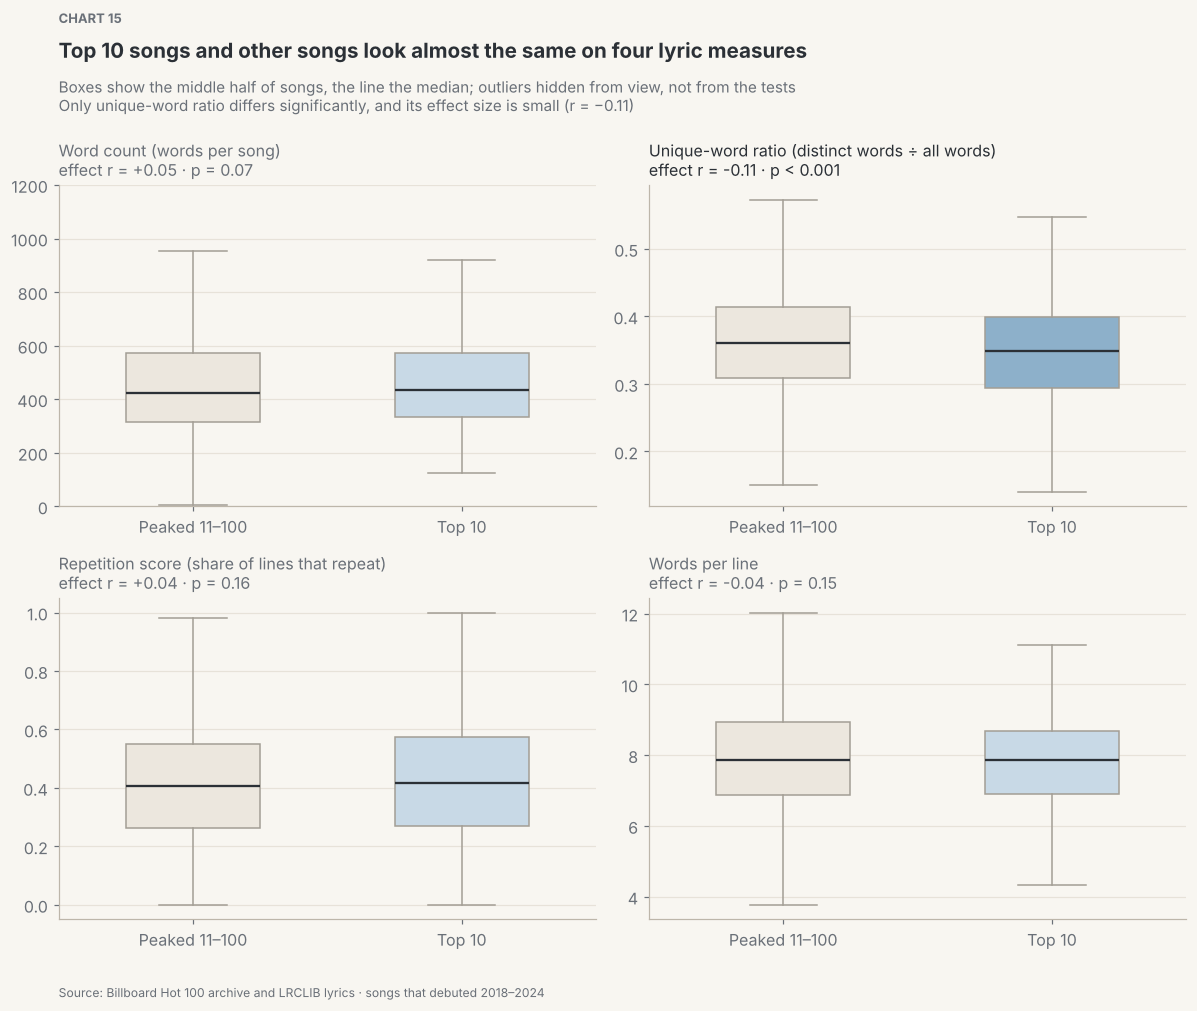

In [57]:
# Chart 15 — four box plots in a 2 x 2 grid, Top 10 vs the rest. Outliers are hidden from view only;
# the tests in the cell above use every song.
titles = {"word_count": "Word count (words per song)",
          "unique_word_ratio": "Unique-word ratio (distinct words ÷ all words)",
          "repetition_score": "Repetition score (share of lines that repeat)",
          "avg_line_length": "Words per line"}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, lyric_cols):
    p, r = q5b.loc[col, "p_value"], q5b.loc[col, "effect_r"]
    sig = p < ALPHA
    parts = ax.boxplot([train.loc[~train["top10"], col].dropna(), train.loc[train["top10"], col].dropna()],
                       tick_labels=["Peaked 11–100", "Top 10"], patch_artist=True, widths=0.5, showfliers=False,
                       medianprops=dict(color=TEXT, linewidth=1.5), boxprops=dict(color=REF),
                       whiskerprops=dict(color=REF), capprops=dict(color=REF))
    for box, colour in zip(parts["boxes"], [PALE, FOCUS_LIGHT if sig else FOCUS_PALE]):
        box.set_facecolor(colour)
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    ax.set_title(f"{titles[col]}\neffect r = {r:+.2f} · {p_text}", fontsize=10.5, loc="left",
                 color=TEXT if sig else MUTED)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[0, 0].set_ylim(0, 1200)
chart_titles(axes[0, 0], 15, "Top 10 songs and other songs look almost the same on four lyric measures",
             "Boxes show the middle half of songs, the line the median; outliers hidden from view, not from the tests\n"
             "Only unique-word ratio differs significantly, and its effect size is small (r = −0.11)",
             source="Source: Billboard Hot 100 archive and LRCLIB lyrics · songs that debuted 2018–2024",
             extra_space=34)
show_chart(fig)

**Finding.** Only unique-word ratio differs significantly: Top 10 songs have a median of 0.348 against 0.361 (p < 0.001),
a small effect (r = -0.11). Word count (p = 0.07), repetition (p = 0.16) and words per line (p = 0.16) do not differ.

**Interpretation.** Lyric form carries little signal about chart success, which answers the lyric part of our research
question. Even the one difference mostly reflects genre: inside each of the four largest genres the unique-word gap is
negligible (r between -0.07 and -0.10) and not significant, while pop, the most successful genre, simply uses the fewest
distinct words. These measures count words without reading them, so topic and sentiment remain untested. The 19 training
songs without lyrics are left out rather than scored 0.

**Theme takeaway:** the month pattern disappears once big same-artist debut weeks are removed (Q5). What did change over
time is the genre make-up of hits, mainly because more country songs reached the chart (Q5a). Lyrics barely distinguish
Top 10 songs (Q5b).

### 4.6 Methodology note: does debut position predict the final peak, or is the question circular?

**Hypothesis.** H₀: debut position is unrelated to reaching the Top 10. H₁: a strong debut predicts a strong peak.

This is not one of the 15 questions. We include it because it is a trap, and falling into it is instructive.

In [58]:
# Method note, naive version: Top 10 rate by debut position (this shows the leakage problem).
print("The naive answer\n" + "-" * 44)
naive = train.copy()
naive["debut_bucket"] = pd.cut(naive["debut_position"], [0, 10, 25, 50, 75, 100],
                               labels=["1-10", "11-25", "26-50", "51-75", "76-100"])
display(
    naive.groupby("debut_bucket", observed=True)
         .agg(songs=("title", "size"), top10=("top10", "sum"))
         .assign(top10_rate_pct=lambda t: (t["top10"] / t["songs"] * 100).round(1))
)

debuted_inside = train[train["debut_position"] <= 10]
print(f"\nSongs debuting at positions 1-10: {len(debuted_inside)}")
print(f"  of which reached the Top 10: {debuted_inside['top10'].sum()} "
      f"({debuted_inside['top10'].mean()*100:.0f}%)")
print("  ^ this is a DEFINITION, not a finding: 'top10' means the song ever")
print("    held a position in 1-10, so debuting there already satisfies it.")

The naive answer
--------------------------------------------


,songs,top10,top10_rate_pct
debut_bucket,,,
1-10,303,303,100.0
11-25,435,29,6.7
26-50,775,37,4.8
51-75,1098,28,2.6
76-100,1682,44,2.6



Songs debuting at positions 1-10: 303
  of which reached the Top 10: 303 (100%)
  ^ this is a DEFINITION, not a finding: 'top10' means the song ever
    held a position in 1-10, so debuting there already satisfies it.


In [59]:
# Method note, honest version: only songs that debuted outside the Top 10.
print("The honest answer — songs that debuted at 11 or below\n" + "-" * 54)
outside = train[train["debut_position"] > 10].copy()
outside["debut_bucket"] = pd.cut(outside["debut_position"], [10, 25, 50, 75, 100],
                                 labels=["11-25", "26-50", "51-75", "76-100"])
debut_test = chi_square(outside, "debut_bucket")
report(debut_test, "Method note: climbing into the Top 10 from outside it")

The honest answer — songs that debuted at 11 or below
------------------------------------------------------
Method note: climbing into the Top 10 from outside it
-----------------------------------------------------
  chi2(3) = 23.7   p = 2.86e-05   Cramer's V = 0.077 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_bucket,,,
11-25,435,29,6.7
26-50,775,37,4.8
51-75,1098,28,2.6
76-100,1682,44,2.6


**Finding.** Debuting in the Top 10 makes a song a Top 10 song by definition, so we only count songs that climbed in; starting higher helps, but only a little.

**Interpretation.** The naive table shows a 100% Top 10 rate for songs debuting at
positions 1-10, which looks like the strongest predictor in the study and is in fact
pure target leakage: `top10` is defined as ever occupying positions 1-10, so a song
debuting there has already met the definition. Any model given `debut_position` would
score superbly and have learned nothing.

Excluding those 303 songs gives the real answer. Among songs debuting at 11 or below,
climbing into the Top 10 still depends on where they start — 6.7% from 11-25 down to
2.6% from 76-100 (p ≈ 2.9×10⁻⁵) — but the effect is small (V = 0.077), far weaker
than prior artist success.

**Caveat.** The leak here is obvious once seen. The general lesson is that a feature
recorded during the outcome window needs checking against the target's *definition*, not
just its timing, and that a suspiciously excellent predictor deserves suspicion first.

### 4.7 What the 15 questions add up to

- Eleven find a clear association that holds up: genre (Q1, Q1a), previous hits and hit ratio (Q2, Q2a, Q2b), concentration (Q3), origin (Q3a, Q3b), same-week debuts (Q4, Q4b) and the change in the genre make-up of hits (Q5a).
- One holds in part: the previous-hit gap is significant in three of five large genres (Q1b).
- Three show that an apparent pattern is explained by something else: the singles advantage (Q4a) and the release season (Q5) both reflect same-week debuts, and lyric form barely separates hits (Q5b).

#### Tested and dropped

These were tested on the same training songs and found no clear difference, so they are not part of the main analysis.

| What we tested | Result |
|---|---|
| Featured artist on the credit, compared within lead-artist history | 9.6% vs 10.4%; no significant difference within either group (p = 0.12 and 0.43) |
| Result of the artist's previous release, within prior-hit groups | Significant only for artists with 1-4 hits (13.3% vs 8.0%, p = 0.017); not for 5-9 or 10+ |
| Unique-word ratio within each genre | Negligible and not significant in all four large genres (summarised in Q5b) |
| Lyrics containing profanity | 10.1% vs 10.5% overall (p = 0.71); one significant genre, country, rests on 8 hits in 40 songs |
| Time from release to chart debut | Small overall gap (V = 0.057) that disappears within artists with and without a previous hit |

**So what:** who releases a song and how it is released are associated with far more of the difference than anything in
the song's lyrics. Every result is an association; checking each pattern against a likely confounder kept misleading
findings out of our conclusions.

## 5. Conclusion

### 5.1 Prioritised insights

Ranked by expected impact against the effort to act on them.

| # | Insight | Evidence | Impact | Feasibility | Verdict |
|---|---|---|---|---|---|
| 1 | Same-week debuts are the strongest release-related association. A song that is the artist's only debut that week reaches the Top 10 at 11.6%; with 5-9 same-week debuts, 2.1%, in both hip-hop and pop. The "single" label shows no association once this is accounted for | Q4 (p < 0.001, V = 0.102), Q4a, Q4b | High: a 5x difference | High: release scheduling is a decision | Worth testing. Spacing out releases is a candidate lever, but only an experiment or a model with artist controls can show it causes higher placement |
| 2 | Artist track record shows the clearest gradients, and it is not actionable. 18.5% for 10+ previous Top 10s vs 5.8% for none; hit ratio is at least as telling; a first-time entrant does far better than a long-time charter without a hit | Q2 (V = 0.158), Q2a (V = 0.166), Q2b | High: about a 3-4x difference | Low: cannot be changed for a given artist | Use for forecasting, not strategy. Test hit count and hit ratio as model features |
| 3 | Top 10 success is concentrated, and established international stars convert unusually well. Ten artists produced 37% of Top 10 songs; outside-US artists 15.8% vs 9.0% | Q3, Q3a, Q3b | Medium: concentration means a few names drive results | Low: cannot be changed | Check every result for single-artist influence, and treat origin as a weak, star-driven signal |
| 4 | Genre shifts the odds about 3.5x, and the make-up of hits is moving. Pop 18.7%, country 5.3%; the gap remains among songs debuting alone; country's share of hits grew, mainly through more country songs charting | Q1 (p < 0.001), Q1a, Q1b, Q5a | Medium: real but V = 0.146 | Low: an artist cannot switch genre on request | Use as a baseline adjustment, and check whether genre effects shift in the 2025-26 test years |
| 5 | Lyric form carries almost no signal, and two apparent patterns were artefacts. The release season and the singles advantage both reflect same-week debuts; debut position meets the target's definition; previous hits had to be recounted to use only information known at debut | Q5b, Q5, Q4a, 4.0c, 4.6 | High: each would have shipped a wrong claim | High: costs one extra check each | Do not invest further in surface lyric measures. Re-test any effect that could be explained by who released the song or how, and check every feature's timing |

### 5.2 Risks and limitations

Data and licensing. The Billboard archive repository declares no licence, and
LRCLIB publishes none on its public docs page; only MusicBrainz is explicitly CC0. Chart
compilations and lyrics are both copyrighted. This work is non-commercial academic
analysis and the raw lyrics should not be redistributed.

Coverage that is not random. 166 songs (3.1%) have no genre, and coverage is worst
for 2026 (93.7%) because recent releases are less tagged — so the most recent year is
also the least complete. 54 songs are missing MusicBrainz data entirely, mostly
initialism titles ("B.I.T.C.H.", "1.5") that defeat the search. Missingness correlates
with title style, which is not random.

Measurement. Genre comes from volunteer tagging, not a taxonomy. 96 songs are
`mixed` because two genres tied. The profanity flag is a keyword list. 109 songs carry
`lyrics_suspect_short` and their lyric features may understate the real text.

Design. The target is a threshold on a continuous outcome: a song peaking at 11 is
counted with one peaking at 100. Nine years is nine observations of any yearly trend.
Same-week debut count is confounded with artist size and we cannot fully separate them; Q3a, Q4a
and Q5a show how often that kind of confound changes the answer.
And crucially, everything here is association, not causation — nothing was randomised.

What would change our conclusions. If playlist and marketing-spend data were
available, we would expect much of the "artist history" effect to be absorbed by them,
since those are the mechanism rather than the cause.

### 5.3 Next steps

1. Fit a baseline model on the 2018-2024 training split (logistic regression with previous Top 10s counted at debut,
   hit ratio, genre and same-week debut bucket) and evaluate it once on the held-out 2025-2026 songs. Report precision
   and recall at a useful threshold, not accuracy: a model that always predicts "no" is 90% accurate and worthless.
2. Compare models with hit count alone, hit ratio alone and both (Q2, Q2a), and test whether pop's smaller history gap
   (Q1b) holds up with a genre-by-history interaction.
3. Check how much a few artists drive each result (Q3, Q3b), for example by refitting without the top five artists.
4. Let the genre effect change over time, since Q5a shows the make-up of hits is shifting, and check whether the model's
   genre weights still fit 2025-2026.
5. Test lyric content, not lyric form: sentiment and topic features, since Q5b rules out the surface measures rather than
   lyrics as a whole.
6. Separate artist size from release strategy using artist fixed effects, which would turn Q4 from an association into
   something closer to a recommendation.

**So what:** the most actionable association is about how a song is released; the clearest gradient is about who
released it; and the lyric hypothesis that motivated the project does not survive contact with the data.

## 6. References

Data sources

1. Hollingshead, M. *Billboard Hot 100 archive* — JSON files for every Billboard Hot 100
   chart, 1958-2026. https://github.com/mhollingshead/billboard-hot-100 (accessed
   September 2026). No licence declared by the repository.
2. *LRCLIB* — open lyrics database and API. https://lrclib.net/docs (accessed September
   2026). No licence stated on the public documentation page.
3. *MusicBrainz* — open music encyclopedia; recordings, release groups and artists.
   https://musicbrainz.org/doc/MusicBrainz_API (accessed September 2026). Core data
   released under CC0; see https://musicbrainz.org/doc/About/Data_License.

Software

4. McKinney, W. (2010). Data structures for statistical computing in Python. *pandas*.
5. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature* 585, 357-362.
6. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific
   computing in Python. *Nature Methods* 17, 261-272.
7. Hunter, J. D. (2007). Matplotlib: a 2D graphics environment. *Computing in Science &
   Engineering* 9(3), 90-95.
   Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source
   Software* 6(60), 3021.
8. Bachmann, M. *RapidFuzz* — fast fuzzy string matching.
   https://github.com/rapidfuzz/RapidFuzz (used in the collection scripts).

Method

9. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
   (Cramér's V, used throughout as the effect size alongside chi-square.)
10. Mann, H. B. & Whitney, D. R. (1947). On a test of whether one of two random variables
    is stochastically larger than the other. *Annals of Mathematical Statistics* 18(1),
    50-60.
11. Kerby, D. S. (2014). The simple difference formula: an approach to teaching nonparametric
    correlation. *Comprehensive Psychology* 3. (Rank-biserial r, the effect size for Mann-Whitney.)

Project code. Collection and cleaning scripts are in `scripts/` (`01_billboard.py`
through `08_features.py`); every column in the analysis file is documented in
`docs/data_dictionary.md`.

**So what:** every number in this notebook traces to a documented source or a script in
this repository, so any claim here can be checked rather than taken on trust.

## 7. AI usage disclosure

Our team used Claude as the primary AI assistant for this project. Through the Claude Code extension in VS Code, we used it to draft and debug Python code for data cleaning, explain statistical functions, and refine written descriptions in this Colab notebook. All AI-generated code and text were independently reviewed by our team. We tested each script, corrected logical errors, and modified the code as needed to ensure that it accurately reflected our data and intended analysis. We also revised AI-assisted explanations to match our own interpretation of the results. To verify the statistical results, we independently recalculated key metrics directly from the raw source data and compared those values with the outputs, tables, and charts produced in the notebook. We then checked that our written interpretations and conclusions were consistent with these verified results.
